## Problem Statement

### Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to bring in more loan business and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

You as a Data scientist at AllLife bank have to build a model that will help the marketing department to identify the potential customers who have a higher probability of purchasing the loan.

### Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and identify which segment of customers to target more.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [1]:
# Installing the libraries with the specified version.
#!pip install numpy==2.1.0 pandas==2.2.2 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.6.1 sklearn-pandas==2.2.0 -q --user

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, f1_score, accuracy_score, precision_score, recall_score, r2_score, confusion_matrix
import scipy
from scipy import stats

from sklearn.preprocessing import StandardScaler

In [3]:
print(f"np: {np.__version__}")
print(f"pd: {pd.__version__}")
print(f"sns: {sns.__version__}")
print(f"sklearn: {sklearn.__version__}")
print(f"scipy: {scipy.__version__}")


np: 2.4.6
pd: 2.3.3
sns: 0.13.2
sklearn: 1.9.0
scipy: 1.18.1


## Loading the dataset

In [4]:
"""
from google.colab import drive
drive.mount('/content/drive/')
df_orig = pd.read_csv(
    "/content/drive/MyDrive/AIML-Projects/PersonalLoan/Loan_Modelling.csv"
)
"""

'\nfrom google.colab import drive\ndrive.mount(\'/content/drive/\')\ndf_orig = pd.read_csv(\n    "/content/drive/MyDrive/AIML-Projects/PersonalLoan/Loan_Modelling.csv"\n)\n'

In [ ]:
#Load the dataset
df_orig = pd.read_csv('../data/raw/Loan_Modelling.csv')
df = df_orig.copy()

## Data Overview

In [6]:
#Visualize the top 5 rows of data
df.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [7]:
#Check the last 5 rows of data
df.tail()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4995,4996,29,3,40,92697,1,1.9,3,0,0,0,0,1,0
4996,4997,30,4,15,92037,4,0.4,1,85,0,0,0,1,0
4997,4998,63,39,24,93023,2,0.3,3,0,0,0,0,0,0
4998,4999,65,40,49,90034,3,0.5,2,0,0,0,0,1,0
4999,5000,28,4,83,92612,3,0.8,1,0,0,0,0,1,1


In [8]:
#Check random 5 rows of data
df.sample(5)

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
4453,4454,37,11,11,94112,3,0.1,2,0,0,0,0,0,0
1732,1733,25,0,88,94566,2,1.8,2,319,0,0,0,1,1
1180,1181,42,17,90,90504,1,0.1,2,0,0,0,0,0,1
958,959,55,29,78,90747,4,2.6,3,0,0,0,0,0,1
2491,2492,38,14,80,92868,2,2.7,1,0,0,0,0,1,0


In [9]:
# Rows and columns of the data
print('Number of Rows: {}   No.of Columns: {}'.format(df.shape[0], df.shape[1]))
df.shape

Number of Rows: 5000   No.of Columns: 14


(5000, 14)

In [10]:
# Information about type of columns and count of non-null values in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


## Statistical Summary of the data

In [11]:
#Check some statistical measures for more insight about data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


* Observations
* Sanity checks

In [12]:
#Check ID variable
df['ID'].nunique()

5000

ID is given as int64. It can be considered as nominal categorical variable. Each data has a distinct ID (5000 unique values). It is just a label and might not add any valuable information for the analysis. This maybe dropped and not considered in the analysis.

In [13]:
#Check ZIPCode variable
df['ZIPCode'].nunique()

467

Zipcode is given as numerical value. Although it contains digits, it can be considered as a categorical variable. There are too many unique values for this variable. Special treatment is needed.

#### Observations



1.  There are 5000 rows of data.Each row has 14 columns.
2.  One of the columns(CCAvg) is of float64 type and remaining are int64 type.
3.  Every column shows there 5000 non-null values. So, there may not be any missing values. We will confirm later.
4.  Probably Income column is in 1000 dollar units. Range is $8000-$224000.
5.  Mortgage is also probably in 1000 dollar units. Range is $0-$635000.
6.  Age is ranging from 23 yrs to 67 yrs.
7.  Experience range is -3 to 43 yrs. There are some negative values for experience. The values need to be corrected.
8.  ID is given as int64. It can be considered as categorical variable. Each data has a  distinct ID (5000 unique values). It is just a label and does not carry any mathematical meaning. This maybe dropped and not considered in the analysis.
9.  Zipcode is given as numerical value. Although it contains digits, it can be considered as a categorical variable. Might not carry any mathematical meaning. There are too many unique values for this variable. This may be dropped and not considered in the analysis.
10. Family size is between 1-4. No descrepancy. It is an ordinal categorical variable.
11. Education ranges from 1-3. This is an ordinal categorical variable.
12.   Following columns have only two values 0 or 1
  1.   Personal_Loan
  2.   CD_Account
  3.   Securities_Account
  4.   Online
  5.   Credit_Card

Personal_Loan is the dependent variable.
  

















#### Sanity Checks

1.   There are no missing values in the data
2.   Data does not contain any duplicate data
3.   'Experience' has some negative values. Correction is needed.


In [14]:
#Check for any missing values
df.isnull().sum().sum()

np.int64(0)

*   There are no missing values in the data


In [15]:
#Check for any duplicate data
df.duplicated().sum()

np.int64(0)


*   There are no duplicate values in the data

##### Observations of 'Experience'

In [16]:
#'Experience' has some negative values. Corrction is needed.
df['Experience'].min()

np.int64(-3)

*   Negative values are converted to positive values by taking the absolute
*   Checking the minimum value after conversion



In [17]:
#Take the absolute value
df['Experience'] = np.abs(df['Experience'])
df['Experience'].min()

np.int64(0)

## Exploratory Data Analysis.

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?

##### Univariate Analysis

In [18]:
#Function to print histplot and boxplot together
def histplot_boxplot(df, feature):
  f, (ax_hist, ax_box) = plt.subplots(2,1,figsize=(8,6), sharex=True, gridspec_kw={'height_ratios':(0.8, 0.2)})
  sns.histplot(df, x=feature, kde=True, ax=ax_hist)
  ax_hist.axvline(df[feature].mean(), color='green')
  ax_hist.axvline(df[feature].median(), color='black')
  sns.boxplot(df, x=feature, showmeans=True, color='orange')

  f.tight_layout(pad = 2)
  f.show()


In [19]:
#Function to print labelled countplot
def label_countplot(df, category):
  print(df[category].value_counts(normalize=True)*100, '\n')
  ax = sns.countplot(df, x=category, hue=category,  legend = False, palette='Spectral')
  # Annotate with actual percentage values
  for p in ax.patches:
    percentage = p.get_height()/df.shape[0]*100
    ax.annotate(f'{percentage:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom')


#####  Univariate Analysis of Numerical Variables

In [20]:
numeric_cols = ['Age', 'Income', 'Mortgage', 'Experience', 'CCAvg']
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,45.338400,11.463166,23.0,35.0,45.0,55.0,67.0
Income,5000.0,73.774200,46.033729,8.0,39.0,64.0,98.0,224.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.0,0.0,101.0,635.0
Experience,5000.0,20.134600,11.415189,0.0,10.0,20.0,30.0,43.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.7,1.5,2.5,10.0


##### Observations on 'Age' data

C:\Users\uksaj_uk\AppData\Local\Temp\ipykernel_31444\1871194036.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  f.show()


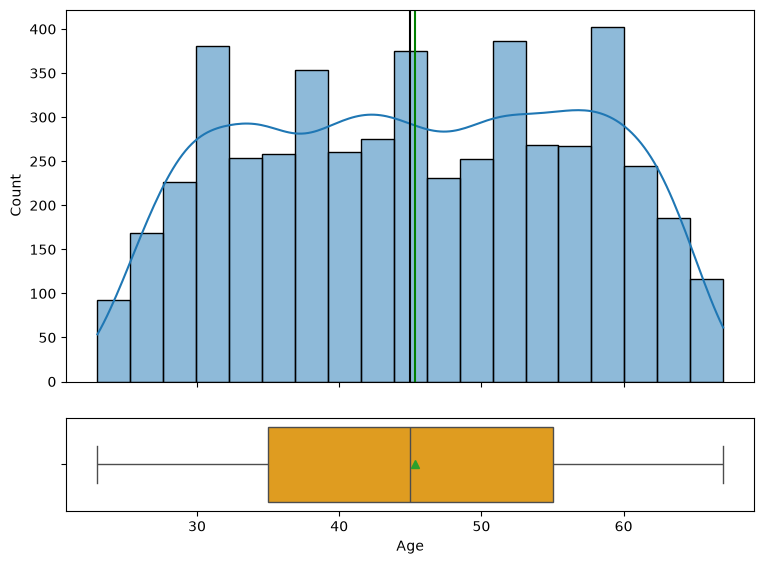

In [21]:
#'Age' variable distribution
histplot_boxplot(df,'Age')


*   'Age' data ranges between 23-67 yrs and does not have any outliers.

*   No skewness in the data



##### Observations on 'Experience' data

C:\Users\uksaj_uk\AppData\Local\Temp\ipykernel_31444\1871194036.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  f.show()


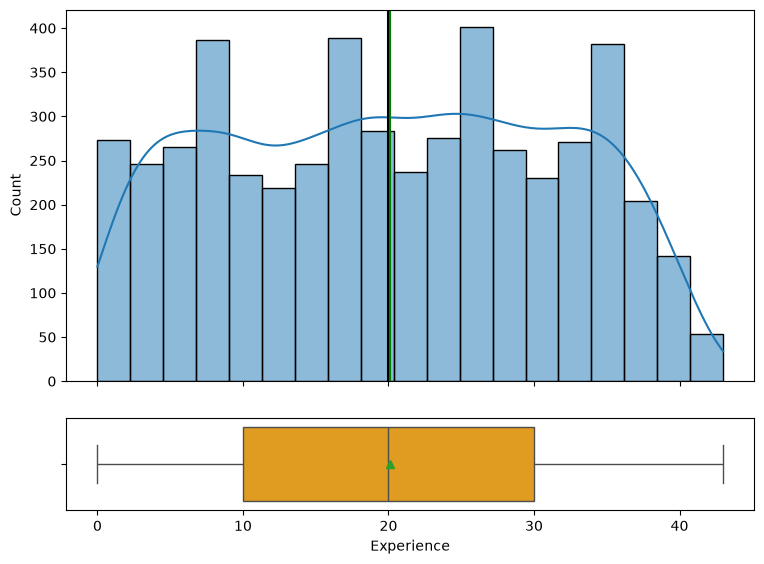

In [22]:
#'Experience' variable distribution
histplot_boxplot(df,'Experience')


*   Experience ranges from 0 to 43 yrs.
*   No skewness in the data.

##### Observations on 'Income' data

C:\Users\uksaj_uk\AppData\Local\Temp\ipykernel_31444\1871194036.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  f.show()


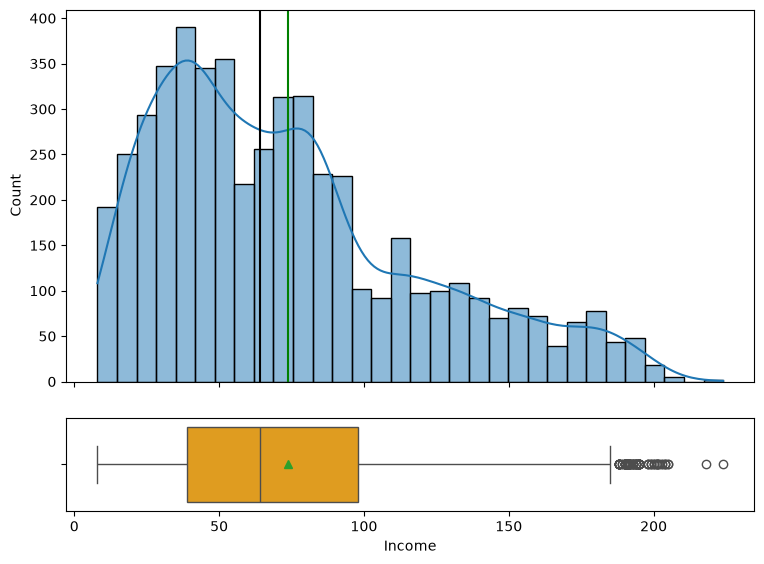

In [23]:
#'Income' variable distribution
histplot_boxplot(df,'Income')



*   'Income' data is positively (right) skewed.
*   It has some outliers on the higher income side.
*   However, these outliers extend beyond the right whisker. So they may represent the actual data and may not have errors.




##### Observations on 'Mortgage' data

C:\Users\uksaj_uk\AppData\Local\Temp\ipykernel_31444\1871194036.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  f.show()


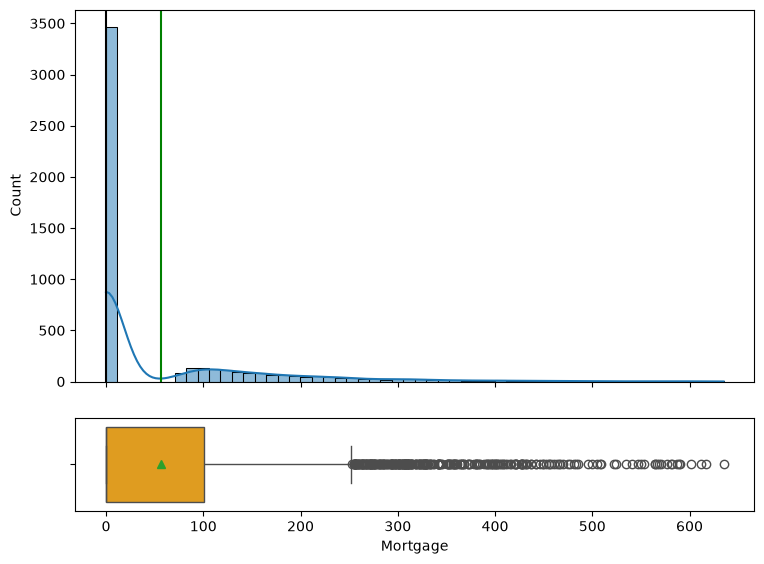

In [24]:
#'Mortgage' variable distribution
histplot_boxplot(df,'Mortgage')


*   'Mortgage' data is highly positively (right) skewed.
*   It has some outliers on the higher mortgage side. There are some large mortgages.
*   However, these outliers extend beyond the right whisker. So they may represent the actual data and may not have errors.

##### Observations on 'CCAvg' data

C:\Users\uksaj_uk\AppData\Local\Temp\ipykernel_31444\1871194036.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  f.show()


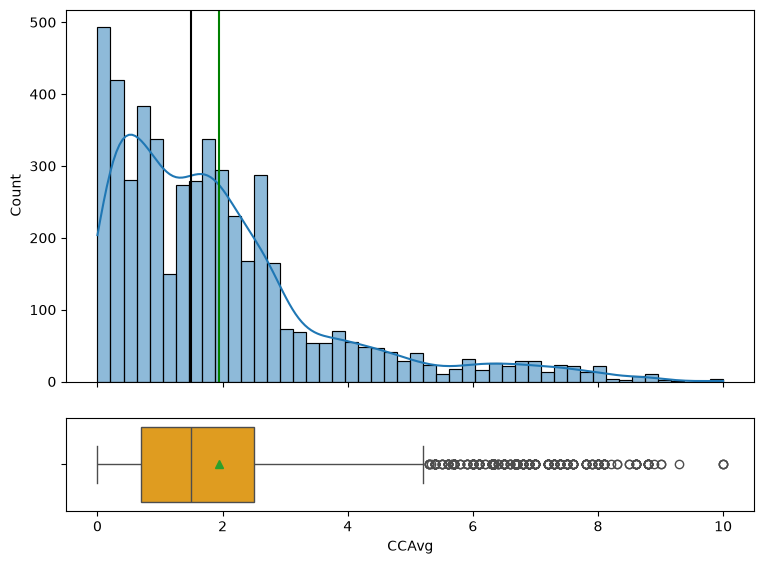

In [25]:
#'CCAvg' variable distribution
histplot_boxplot(df,'CCAvg')


*   'CCAvg' data is positively (right) skewed.
*   It has some outliers on the higher spending side.
*   However, these outliers extend beyond the right whisker. So they may represent the actual data and may not have errors.

#### Univariate Analysis of Categorical Variables

In [26]:
cat_variables = ['Securities_Account', 'CD_Account', 'Online', 'CreditCard',   'Education', 'Family']

##### Observations on 'Securities_Account' data

Securities_Account
0    89.56
1    10.44
Name: proportion, dtype: float64 



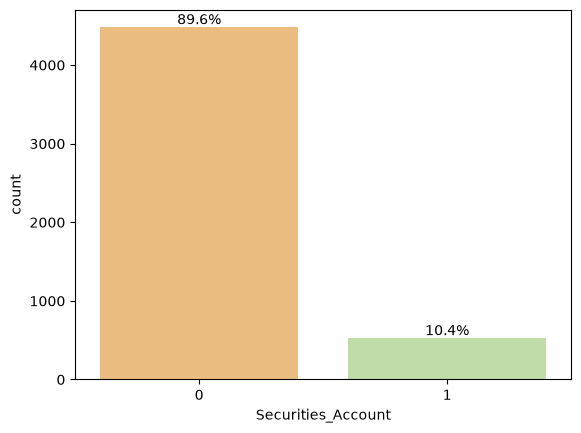

In [27]:
#'Securities_Account' variable
label_countplot(df,'Securities_Account');




*   'Security_Account' data has a high imbalance between the classes.
*   Only about 10% of the customers have 'Security_Account' where as 90% don't have. This imbalance needs to be considered while splitting the data.



##### Observations on 'CD_Account' data

CD_Account
0    93.96
1     6.04
Name: proportion, dtype: float64 



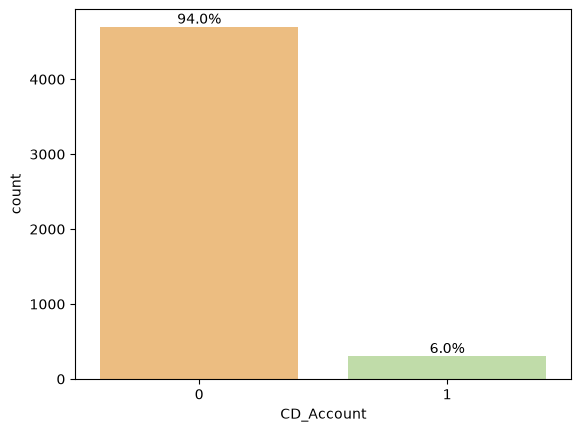

In [28]:
#'CD_Account' variable
label_countplot(df,'CD_Account');



*   'CD_Account' data has a high imbalance between the two classes.
*   Only about 6% of the customers have 'CD_Account' where as 90% don't have. This imbalance needs to be considered while splitting the data.

##### Observations on 'Online' data

Online
1    59.68
0    40.32
Name: proportion, dtype: float64 



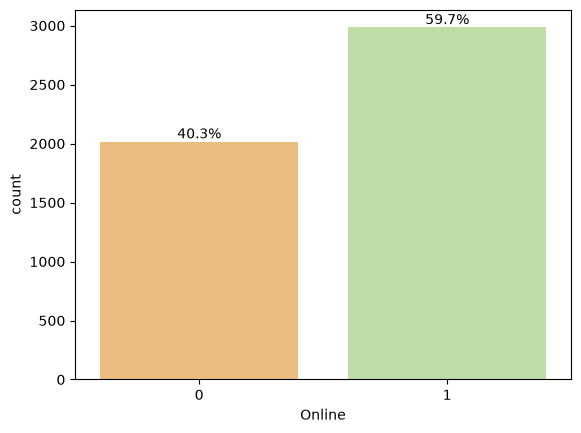

In [29]:
#'Online' variable
label_countplot(df,'Online');


*   About 60% of the customers have 'Online' presence whereas 40% don't use this internet banking feature.

#####Observations on 'CreditCard' data

CreditCard
0    70.6
1    29.4
Name: proportion, dtype: float64 



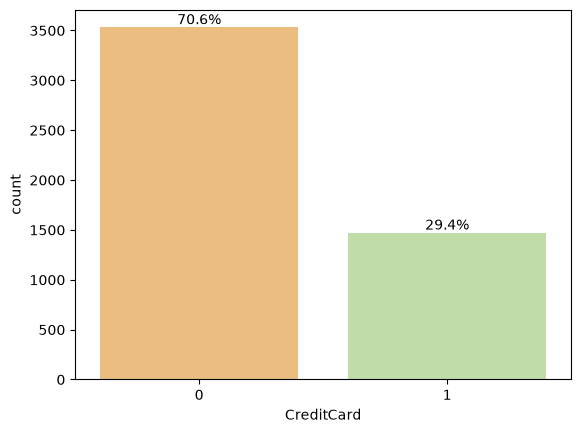

In [30]:
#'CreditCard' variable
label_countplot(df,'CreditCard');

*   'CreditCard' data has a high imbalance between the two classes.
*   Only about 30% of the customers have 'CreditCard' where as 70% don't have. This imbalance needs to be considered while splitting the data.

#####Observations on 'Family' data

Family
1    29.44
2    25.92
4    24.44
3    20.20
Name: proportion, dtype: float64 



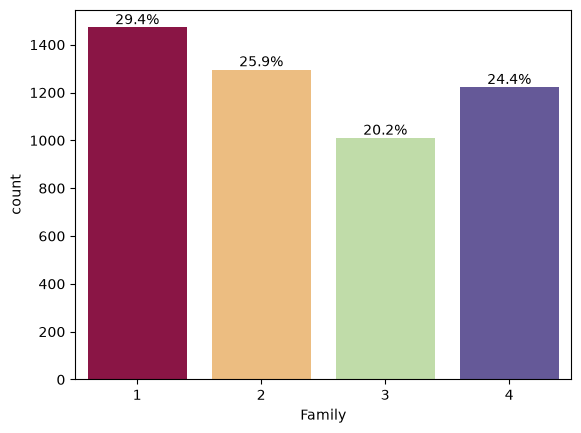

In [31]:
#'Family' variable
label_countplot(df,'Family');



*   Customer's family size ranges from 1-4
*   Data is more evenly distributed as per the 'Family' size

##### Observations on 'Education' data

Education
1    41.92
3    30.02
2    28.06
Name: proportion, dtype: float64 



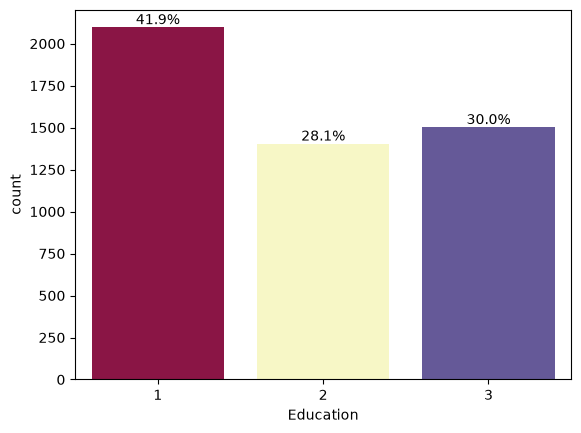

In [32]:
#'Education' variable
label_countplot(df,'Education');




*   Nearly 42% of the customers have undergraduate education.
*   About 28% graduates and 30% Advanced professionals.

##### Observations on Response variable 'Personal_Loan' data

Personal_Loan
0    90.4
1     9.6
Name: proportion, dtype: float64 



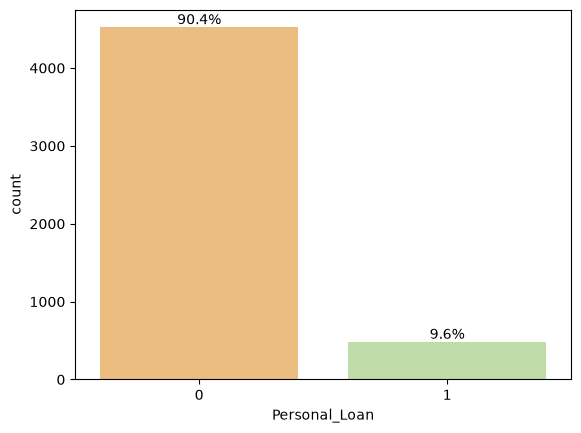

In [33]:
#'Personal_Loan' variable distribution
label_countplot(df,'Personal_Loan')


*   'Personal_Loan' is the dependent or response or target variable
*   This data is highly imbalanced. It is important to consider this while splitting the data.

##### Bivariate Analysis



*   We will analyze how the different explonatory variables data are distribued among the two classes of the target variable 'Personal_Loan'


In [34]:
#Function to compare
def hist_box_wrt_target(df, feature, target):
  target_values = df[target].unique()
  n = df[target].nunique()
  f, axs = plt.subplots(1, n, figsize=(10,5))
  for i in range(0,n):
    axs[i].set_title('Distribution of ' + target + " "+ str(target_values[i]))
    sns.histplot(df[df[target]== target_values[i]], x=feature, kde=True, ax = axs[i], color = 'royalblue', binrange=[df[feature].min(), df[feature].max()], bins=10)

  plt.figure(figsize=(10,5))
  sns.boxplot(df, x=target, y=feature, hue = target, legend=False, palette='gist_rainbow');
  plt.show()

##### Observations of 'Age' against 'Personal_Loan'

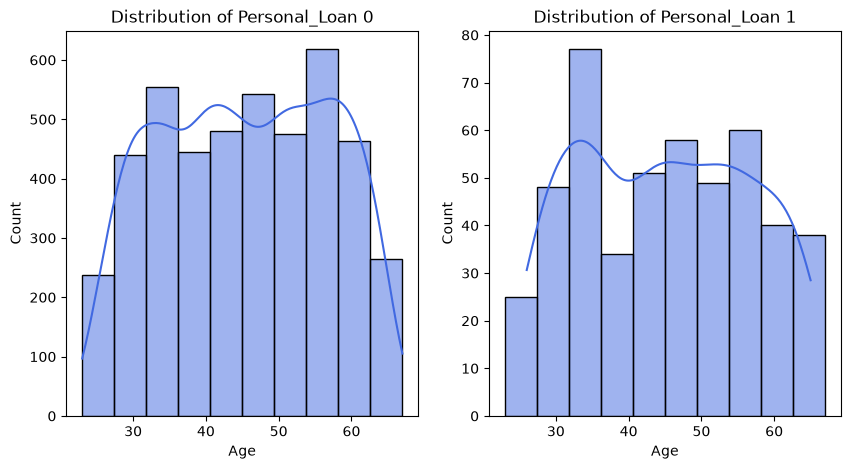

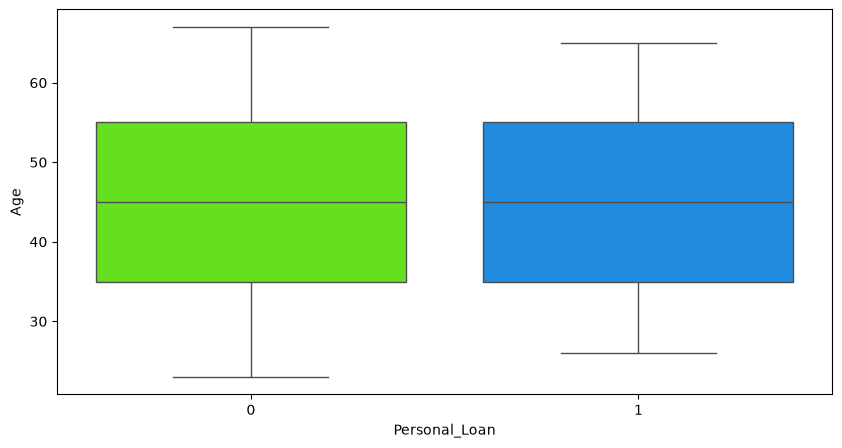

In [35]:
hist_box_wrt_target(df, 'Age', 'Personal_Loan')



*   Boxplots do not show any significant differences in the median of the two classes.
*   This is probalby suggesting that 'Age' may not be a very important feature in deciding the potential purchaser of the loan. We will verify later.



##### Observations of 'Experience' against 'Personal_Loan'

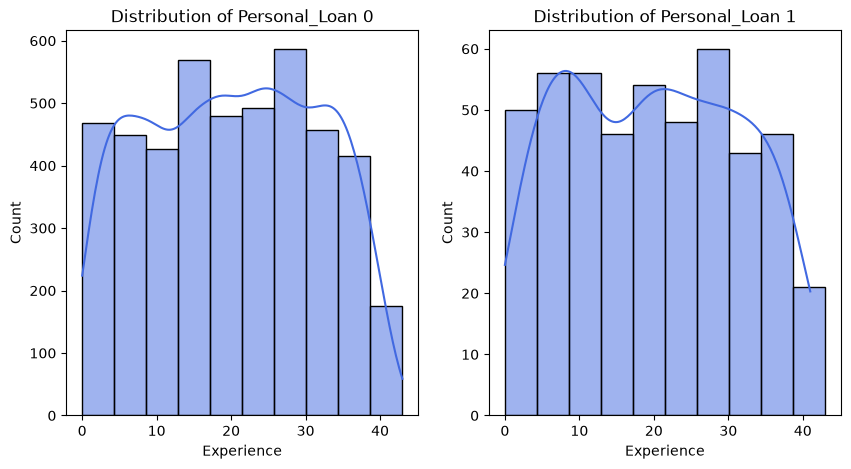

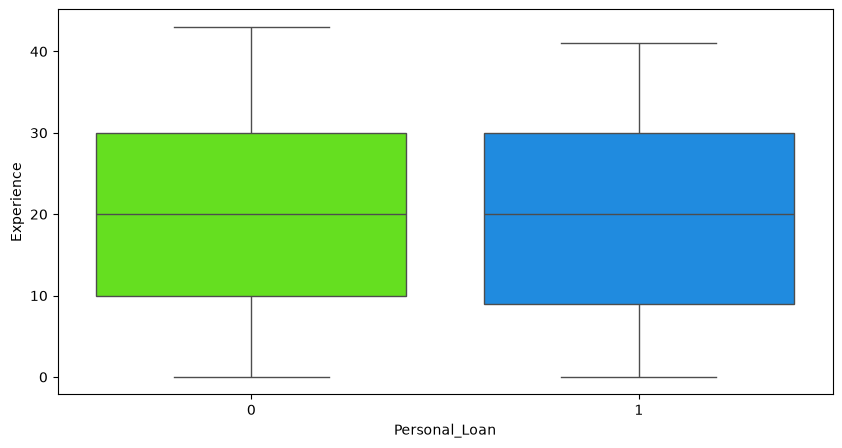

In [36]:
hist_box_wrt_target(df, 'Experience', 'Personal_Loan')


*   Boxplots do not show any significant differences in the median of the two classes.
*   This is probalby suggesting that 'Experience' may not be a very important feature in deciding the potential purchaser of the loan. We will verify later.

##### Observations of 'CCAvg' vs 'Personal_Loan'

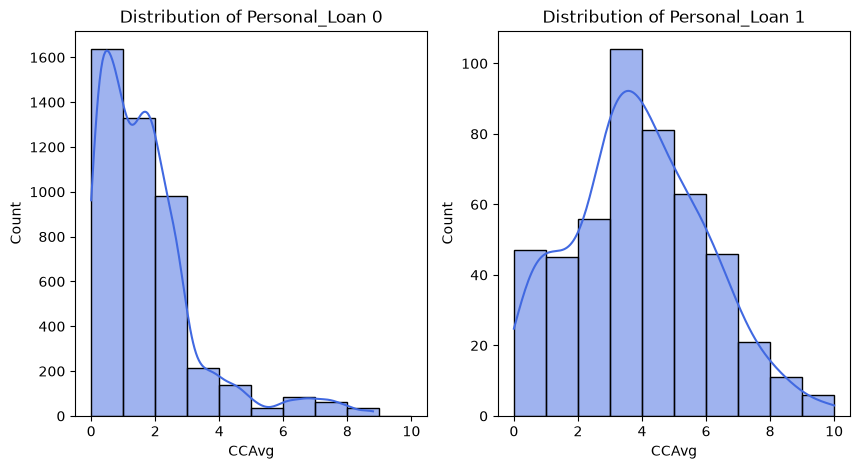

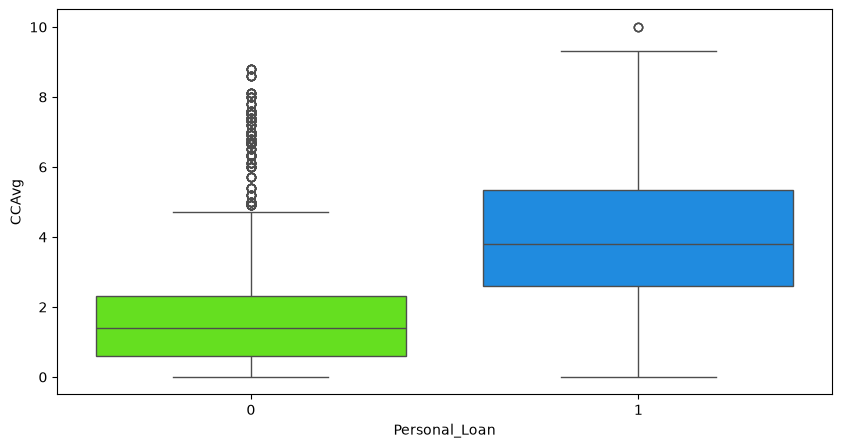

In [37]:
hist_box_wrt_target(df, 'CCAvg', 'Personal_Loan')


*   Boxplots do show some differences in the median of the two classes.
*   This suggests that customers with higher creditcard spending maybe morelikely to purchase the Personal_Loan. We will verify during the analysis.

##### Observations of 'Income' vs 'Personal_Loan'

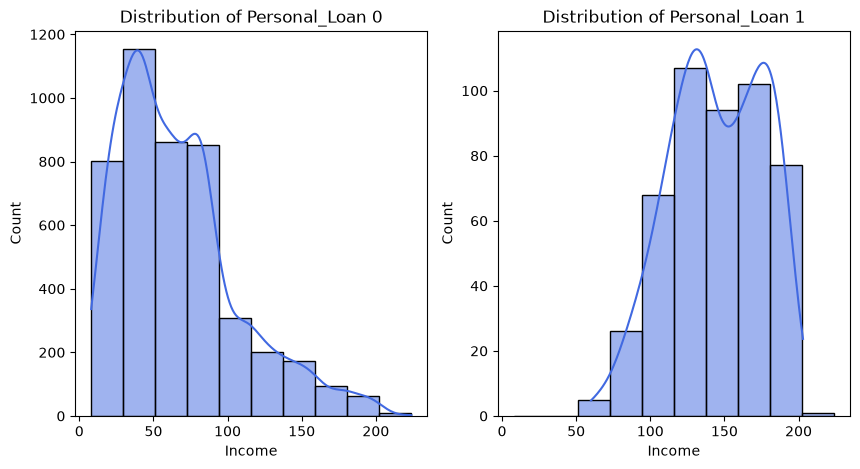

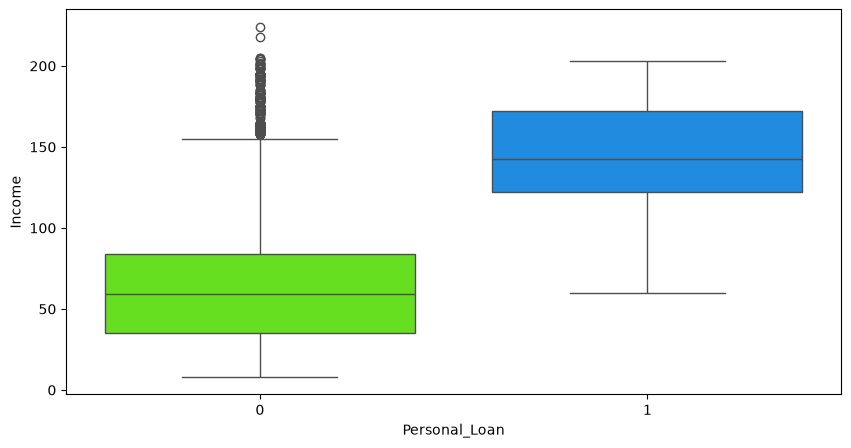

In [38]:
hist_box_wrt_target(df, 'Income', 'Personal_Loan')


*   Boxplots do show some differences in the median of the two classes.
*   This suggests that customers with higher income maybe morelikely to purchase the Personal_Loan. We will verify during the analysis.

##### Observations of 'Mortgage' vs 'Personal_Loan'

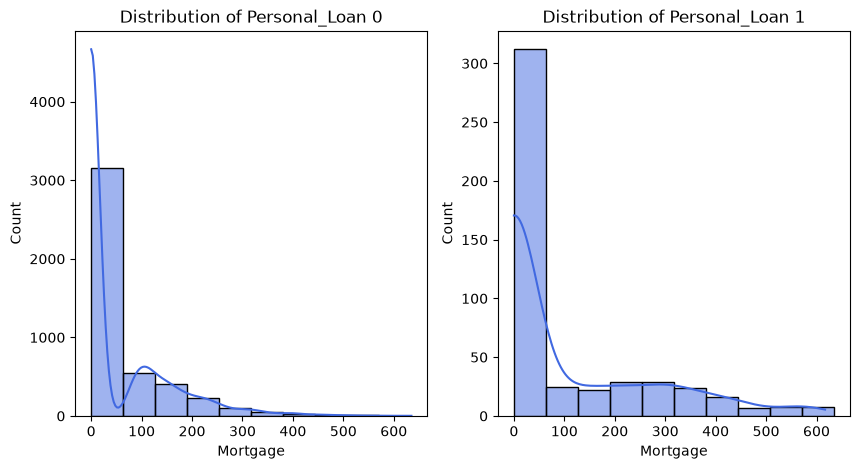

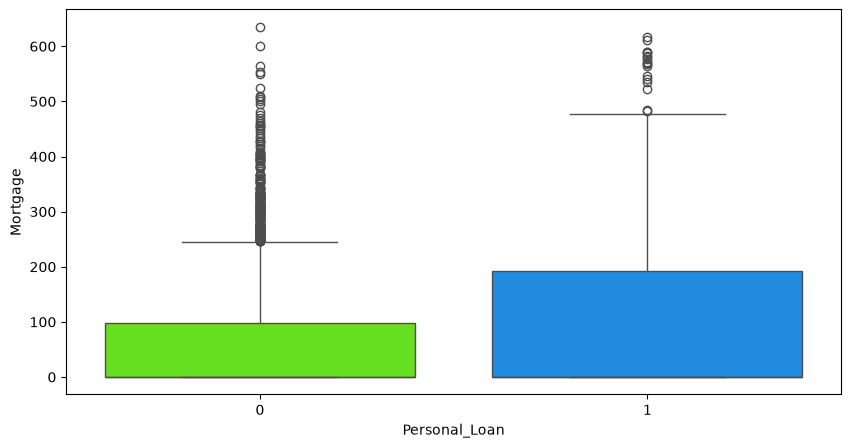

In [39]:
hist_box_wrt_target(df, 'Mortgage', 'Personal_Loan')

In [40]:
#Compute a simple cross tabulation of an independent variable and a dependent variable.
def stacked_crosstab(df, feature_var, target_var):
  sorter = df[target_var].value_counts().index[0]
  tab = pd.crosstab(df[feature_var], df[target_var], normalize='index').sort_values(by=sorter, ascending=False)
  print(tab, '\n')
  tab.plot(kind = 'bar', stacked=True)
  plt.legend(loc = 'upper right', bbox_to_anchor=(1,1))


##### Observations of 'Securities_Account' vs 'Personal_Loan'

Personal_Loan              0         1
Securities_Account                    
0                   0.906208  0.093792
1                   0.885057  0.114943 



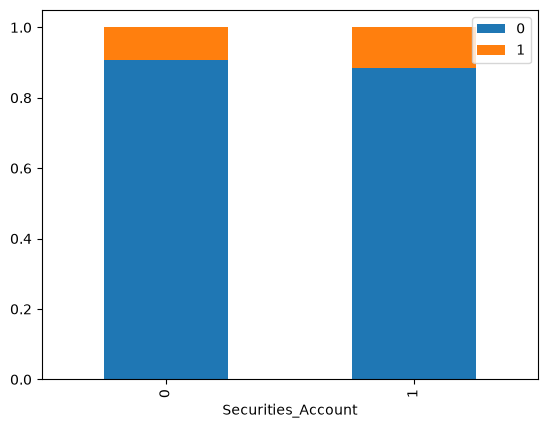

In [41]:

stacked_crosstab(df, 'Securities_Account', 'Personal_Loan')



*   This plot suggests no significant differences in loan purchasing with respect to having Securities_Account.

##### Observations of 'CS_Account' vs 'Personal_Loan'

Personal_Loan         0         1
CD_Account                       
0              0.927629  0.072371
1              0.536424  0.463576 



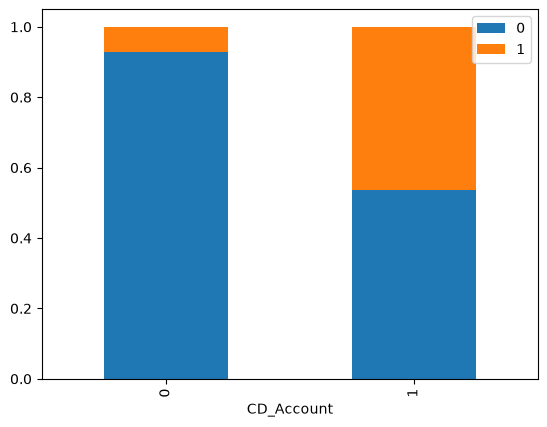

In [42]:
stacked_crosstab(df, 'CD_Account', 'Personal_Loan')

*   This plot suggests significant differences in loan purchasing with respect to having CD_Account. to pur

*   Customers with 'CD_Account' maybe more inclined to purchase the Personal_Loan
*   46% of Customers that has 'CD_Account' purchased the loan whereas only 7% of the customers without the 'CD_Account' purchased the loan.

##### Observations of 'Online' vs 'Personal_Loan'

Personal_Loan        0        1
Online                         
0              0.90625  0.09375
1              0.90248  0.09752 



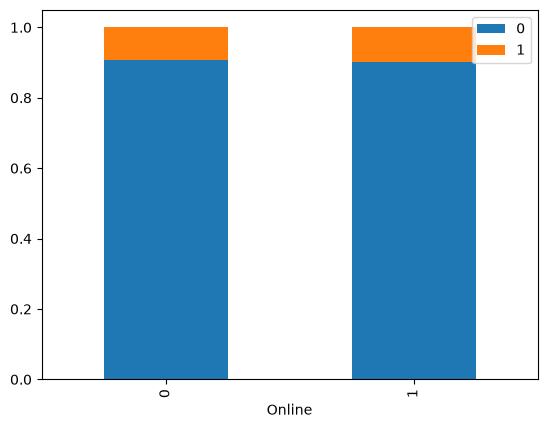

In [43]:
stacked_crosstab(df, 'Online', 'Personal_Loan')


*   Based on this plot, the customers 'Online' banking usage may not be a strong indicator of whether or not they puchase the loan.

##### Observations of 'CreditCard' vs 'Personal_Loan'

Personal_Loan         0         1
CreditCard                       
0              0.904533  0.095467
1              0.902721  0.097279 



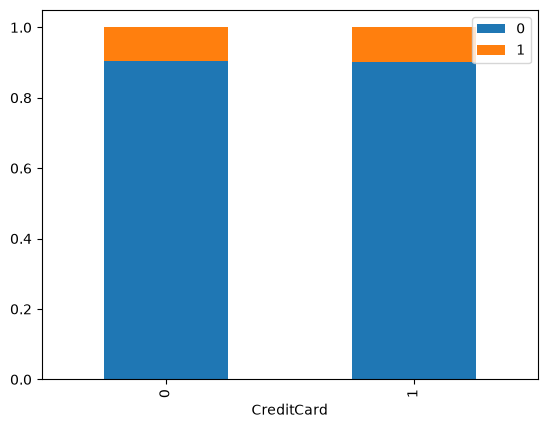

In [44]:
stacked_crosstab(df, 'CreditCard', 'Personal_Loan')


*  Based on this plot, the customers having CreditCard may not be a strong indicator of whether or not they puchase the loan.

##### Observations of 'Education' vs 'Personal_Loan'

Personal_Loan         0         1
Education                        
1              0.955630  0.044370
2              0.870278  0.129722
3              0.863424  0.136576 



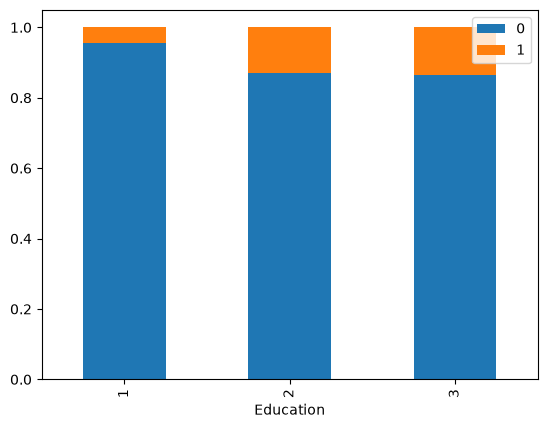

In [45]:
stacked_crosstab(df, 'Education', 'Personal_Loan')


*   Based on this plot, 'Education' maybe an important factor in the loan purchasing characteristic of the customer.  

##### Observations of 'Family' vs 'Personal_Loan'

Personal_Loan         0         1
Family                           
1              0.927310  0.072690
2              0.918210  0.081790
4              0.890344  0.109656
3              0.868317  0.131683 



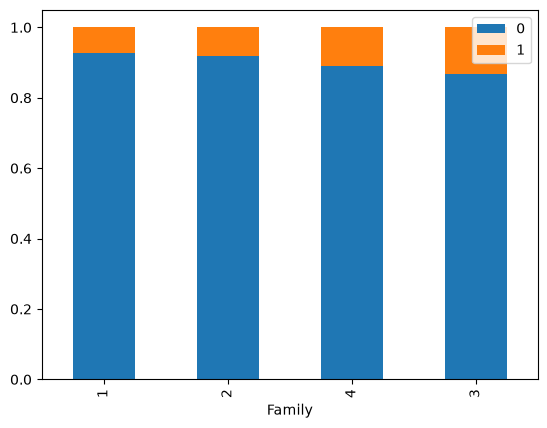

In [46]:
stacked_crosstab(df, 'Family', 'Personal_Loan')

*   Based on this plot, 'Family' size has influence on purchasing the loan

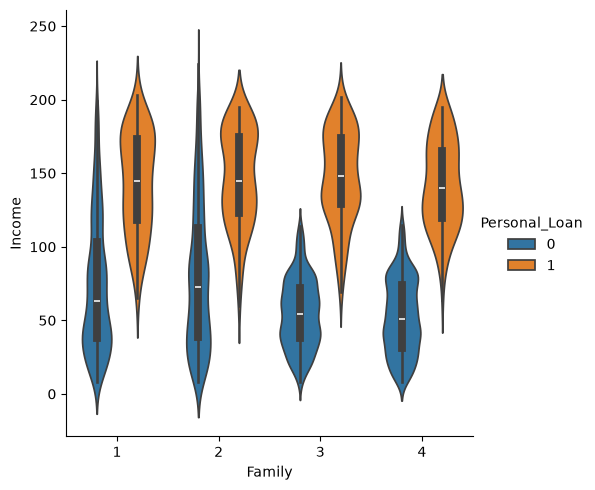

In [47]:
sns.catplot(df, x='Family', y='Income', hue='Personal_Loan', kind='violin')


*   Based on this plot, higher income customers are more like to purchase the loan. This trend is the same for all family sizes.

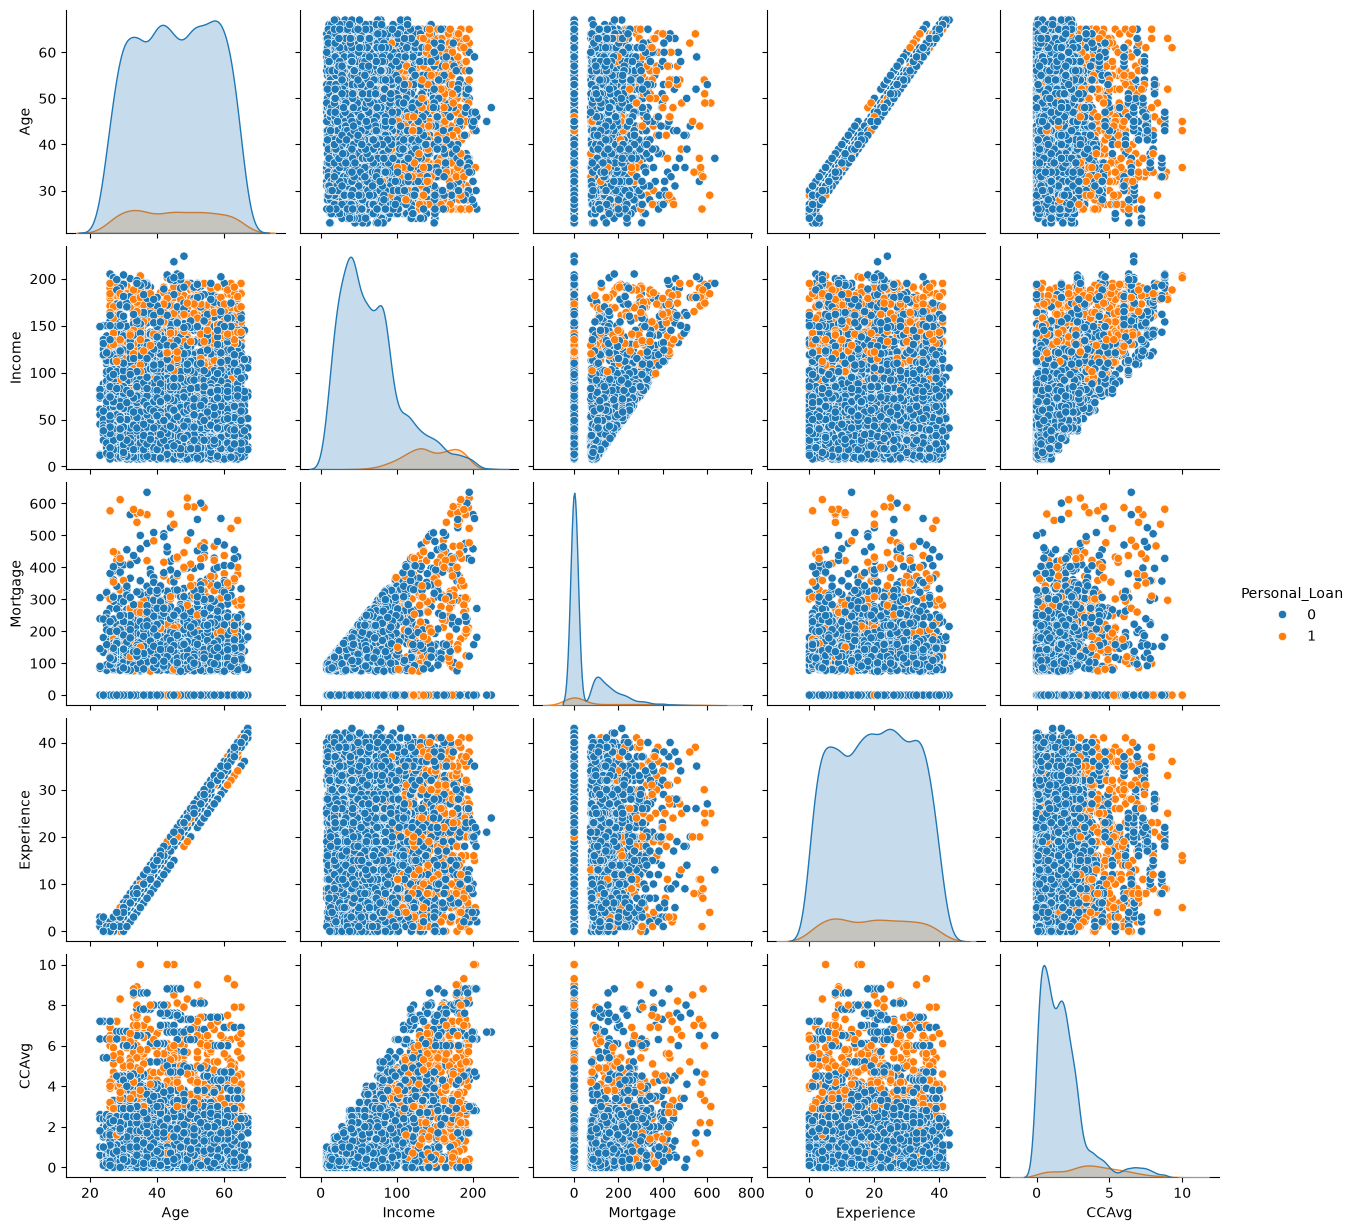

In [48]:
sns.pairplot(df, vars = numeric_cols, diag_kind='kde', hue='Personal_Loan')


*  This plot suggests that 'Age' and 'Experience' are highly correlated with eatch other and may cause issues with multi-collinearity.


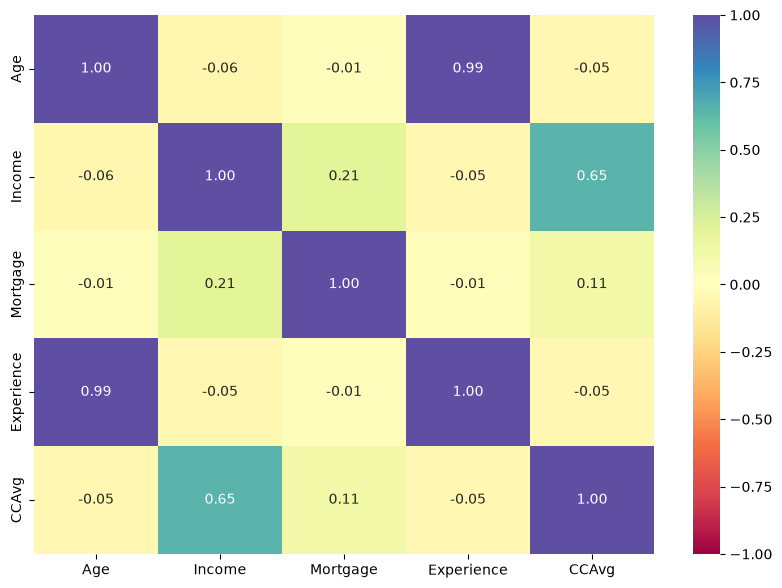

In [49]:
plt.figure(figsize=(10,7))
#HeatMap showing correlation
sns.heatmap(df[numeric_cols].corr(), vmin=-1, vmax=1, annot=True, fmt='0.2f', cmap='Spectral');

*  This plot confirms the observation shown in pairplot above that 'Age' and 'Experience' are highly correlated with each other and this may cause issues with multi-collinearity.

## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

#### Missing value treatment
There are no Missing Values. No treatment is needed.

In [50]:
#Check for any missing values
df.isnull().sum().sum()

np.int64(0)

#### Treatment of categorical variables

##### Treatment of 'ID' column
ID is a categorical variable. This does not add any mathematical meaning as each row has a unique ID. This column is dropped.

In [51]:
df_ID = df
#dropping ID column as this variable does not contribute to the model
df.drop(['ID'], axis=1, inplace=True)

##### Treatment of ZIPCode variable

In [52]:
df['ZIPCode'].nunique()

467

Zip code is given as a numericl data. However, ZIP code does not carry mathematical meaning.
ZIPCode is treated as categorical variable.
However, there are several unique values for ZIPCode.

*   Let us consider only the first two digits.
*   Convert the datatype to str (first two digits)

Then, we can use Onehot encoding on these categorical variables.


In [53]:
df['ZIPCode'] =df['ZIPCode']//1000

Feature engineering (if needed)

In [54]:
df['ZIPCode'].value_counts()

ZIPCode
94    1472
92     988
95     815
90     703
91     565
93     417
96      40
Name: count, dtype: int64

In [55]:
df.head()

,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,25,1,49,91,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91,4,1.0,2,0,0,0,0,0,1


In [56]:
df['ZIPCode'] = df['ZIPCode'].astype(str)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5000 non-null   int64  
 1   Experience          5000 non-null   int64  
 2   Income              5000 non-null   int64  
 3   ZIPCode             5000 non-null   object 
 4   Family              5000 non-null   int64  
 5   CCAvg               5000 non-null   float64
 6   Education           5000 non-null   int64  
 7   Mortgage            5000 non-null   int64  
 8   Personal_Loan       5000 non-null   int64  
 9   Securities_Account  5000 non-null   int64  
 10  CD_Account          5000 non-null   int64  
 11  Online              5000 non-null   int64  
 12  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 507.9+ KB


In [57]:
df.head()

,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,25,1,49,91,4,1.6,1,0,0,1,0,0,0
1,45,19,34,90,3,1.5,1,0,0,1,0,0,0
2,39,15,11,94,1,1.0,1,0,0,0,0,0,0
3,35,9,100,94,1,2.7,2,0,0,0,0,0,0
4,35,8,45,91,4,1.0,2,0,0,0,0,0,1


##### OneHot Encoding

In [58]:
df = pd.get_dummies(df, columns=['Education','Family','ZIPCode'])
df.head()

,Age,Experience,Income,CCAvg,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard,...,Family_2,Family_3,Family_4,ZIPCode_90,ZIPCode_91,ZIPCode_92,ZIPCode_93,ZIPCode_94,ZIPCode_95,ZIPCode_96
0,25,1,49,1.6,0,0,1,0,0,0,...,False,False,True,False,True,False,False,False,False,False
1,45,19,34,1.5,0,0,1,0,0,0,...,False,True,False,True,False,False,False,False,False,False
2,39,15,11,1.0,0,0,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False
3,35,9,100,2.7,0,0,0,0,0,0,...,False,False,False,False,False,False,False,True,False,False
4,35,8,45,1.0,0,0,0,0,0,1,...,False,False,True,False,True,False,False,False,False,False


#### Multicollinearity Treatment

The columns 'Age' and 'Experience are highly positively correlated. It is better to drop a one of these columns to avoid multi-collinearity.
Let us drop 'Experience' column as we have previously seen some negative values as well in the original data.

In [59]:
df.drop('Experience', axis=1, inplace=True)
df.head()

,Age,Income,CCAvg,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard,Education_1,...,Family_2,Family_3,Family_4,ZIPCode_90,ZIPCode_91,ZIPCode_92,ZIPCode_93,ZIPCode_94,ZIPCode_95,ZIPCode_96
0,25,49,1.6,0,0,1,0,0,0,True,...,False,False,True,False,True,False,False,False,False,False
1,45,34,1.5,0,0,1,0,0,0,True,...,False,True,False,True,False,False,False,False,False,False
2,39,11,1.0,0,0,0,0,0,0,True,...,False,False,False,False,False,False,False,True,False,False
3,35,100,2.7,0,0,0,0,0,0,False,...,False,False,False,False,False,False,False,True,False,False
4,35,45,1.0,0,0,0,0,0,1,False,...,False,False,True,False,True,False,False,False,False,False


#### Outliers
*   Some of the data has outliers ('Income', 'Mortgage' and 'CCAvg')
*   However, the outliers are continuously extend beyond the right whisker. They may represent acutal data.
No outlier treatment is needed.

#### Data Imbalance


While splitting the data, stratification is needed to

*   Some of the data columns are very imbalanced
*   Stratification ensures the train test splits represent the same proportion of imbalance as the original data for accurate predictions.

## Model Building

Initilize global random state variable to be used.
This helps reproducing the similar results across multiple runs.

In [60]:
RS=42

#### Identify Independent and Dependent Variables

In [61]:
# defining the explanatory (independent) and response (dependent) variables
X = df.drop(["Personal_Loan"], axis=1)
y = df["Personal_Loan"]


### Split the data set into training and test data sets
*   Use stratify=y since the data is highly imbalanced.
*   Using 80-20 train-test split

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state = RS)

In [63]:
#Check the distribution of classes in train and test and original data
print("Percentage of classes in data set:")
print(y_train.value_counts(normalize=True))
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Percentage of classes in data set:
Personal_Loan
0    0.904
1    0.096
Name: proportion, dtype: float64
Shape of Training set :  (4000, 22)
Shape of test set :  (1000, 22)
Percentage of classes in training set:
Personal_Loan
0    0.904
1    0.096
Name: proportion, dtype: float64
Percentage of classes in test set:
Personal_Loan
0    0.904
1    0.096
Name: proportion, dtype: float64


### Model Evaluation Criterion

In [64]:
feature_names = list(X_train.columns)
feature_names

['Age',
 'Income',
 'CCAvg',
 'Mortgage',
 'Securities_Account',
 'CD_Account',
 'Online',
 'CreditCard',
 'Education_1',
 'Education_2',
 'Education_3',
 'Family_1',
 'Family_2',
 'Family_3',
 'Family_4',
 'ZIPCode_90',
 'ZIPCode_91',
 'ZIPCode_92',
 'ZIPCode_93',
 'ZIPCode_94',
 'ZIPCode_95',
 'ZIPCode_96']

##### Functions to compute the model performance parameters

In [65]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )
    return df_perf

##### Function to print the confusion matrix

In [66]:
def plot_confusion_matrix(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # Predict the target values using the provided model and predictors
    y_pred = model.predict(predictors)

    # Compute the confusion matrix comparing the true target values with the predicted values
    cm = confusion_matrix(target, y_pred)

    # Create labels for each cell in the confusion matrix with both count and percentage
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)    # reshaping to a matrix

    # Set the figure size for the plot
    plt.figure(figsize=(6, 4))

    # Plot the confusion matrix as a heatmap with the labels
    sns.heatmap(cm, annot=labels, fmt="")

    # Add a label to the y-axis
    plt.ylabel("True label")

    # Add a label to the x-axis
    plt.xlabel("Predicted label")

##### Function to Visualize Tree

In [67]:
#Function to visualize the tree
def visualize_tree(model, feature_names):
  # set the figure size for the plot
  plt.figure(figsize=(25, 25))

  # plotting the decision tree
  out = tree.plot_tree(
      model,                          # decision tree classifier model
      feature_names=feature_names,    # list of feature names in the dataset
      filled=True,                    # fill the nodes with colors based on class
      fontsize=9,                     # font size for the node text
      node_ids=False,                 # do not show the ID of each node
      class_names=['NoLoan','Loan'],               # whether or not to display class names
  )

  # add arrows to the decision tree splits if they are missing
  for o in out:
      arrow = o.arrow_patch
      if arrow is not None:
          arrow.set_edgecolor("black")    # set arrow color to black
          arrow.set_linewidth(1)          # set arrow linewidth to 1

  # displaying the plot
  plt.show()

##### Function to Visualize Tree as text

In [68]:
def show_tree_as_text(model, feature_names):
  # Text report showing the rules of a decision tree -
  print(tree.export_text(model, feature_names=feature_names, show_weights=True))

#### Plotting Feature Importances

In [69]:
def plot_feature_importances(model, feature_names):
  # importance of features in the tree building
  importances = model.feature_importances_
  indices = np.argsort(importances)

  plt.figure(figsize=(8, 8))
  plt.title("Feature Importances")
  plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
  plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
  plt.xlabel("Relative Importance")
  plt.show()

#### Print Tree parameters

In [70]:
#Function to print the tree parameters
def print_tree_parameters(model):
  print(f"Max depth: {model.tree_.max_depth}")
  print(f"Max leaf nodes: {np.sum(model.tree_.children_left == -1)}")
  print(f"Min samples split: {model.min_samples_split}")


## Models

#### Model0 - Decision Tree (Unscaled Data)

In [71]:
#Basic model with no standardization
model0 = DecisionTreeClassifier(criterion='gini', random_state=RS)
model0.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [72]:
#Performance of the basic model on train data
model0_train_perf = model_performance_classification(model0, X_train, y_train)
model0_train_perf

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


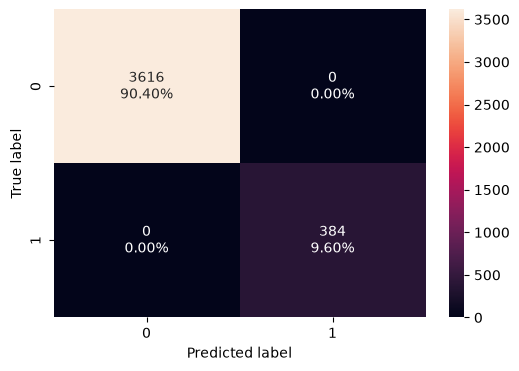

In [73]:
#Confusion Matrix of the basic model on train data
plot_confusion_matrix(model0, X_train, y_train)

In [74]:
#Performance of the basic model on test data
model0_test_perf = model_performance_classification(model0, X_test, y_test)
model0_test_perf

,Accuracy,Recall,Precision,F1
0,0.986,0.947917,0.91,0.928571


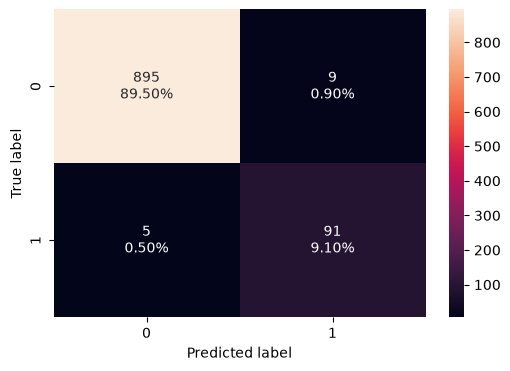

In [75]:
#Confusion Matrix of the basic model on test data
plot_confusion_matrix(model0, X_test, y_test)

Overall there are 14(9 FP + 5 FN) errors made by the model.

##### Feature names and importances

In [76]:
feature_names = list(X_train.columns)
feature_names

['Age',
 'Income',
 'CCAvg',
 'Mortgage',
 'Securities_Account',
 'CD_Account',
 'Online',
 'CreditCard',
 'Education_1',
 'Education_2',
 'Education_3',
 'Family_1',
 'Family_2',
 'Family_3',
 'Family_4',
 'ZIPCode_90',
 'ZIPCode_91',
 'ZIPCode_92',
 'ZIPCode_93',
 'ZIPCode_94',
 'ZIPCode_95',
 'ZIPCode_96']

In [77]:
importances0 = model0.feature_importances_
indices0 = np.argsort(importances0)
importances0

array([2.86624238e-02, 4.10986753e-01, 6.16833350e-02, 1.12036517e-02,
       1.92047689e-03, 1.83614628e-02, 1.92047689e-03, 0.00000000e+00,
       2.97139067e-01, 4.72117236e-03, 5.18528761e-03, 9.56637552e-03,
       3.36083456e-03, 6.27008918e-02, 7.20014573e-02, 1.24830998e-03,
       2.25814316e-03, 1.37048957e-04, 3.97154233e-03, 2.97128918e-03,
       0.00000000e+00, 0.00000000e+00])

##### Visualization of the decision tree with scaled and balanced data

In [78]:
#Print Tree parameters
print_tree_parameters(model0)

Max depth: 13
Max leaf nodes: 69
Min samples split: 2


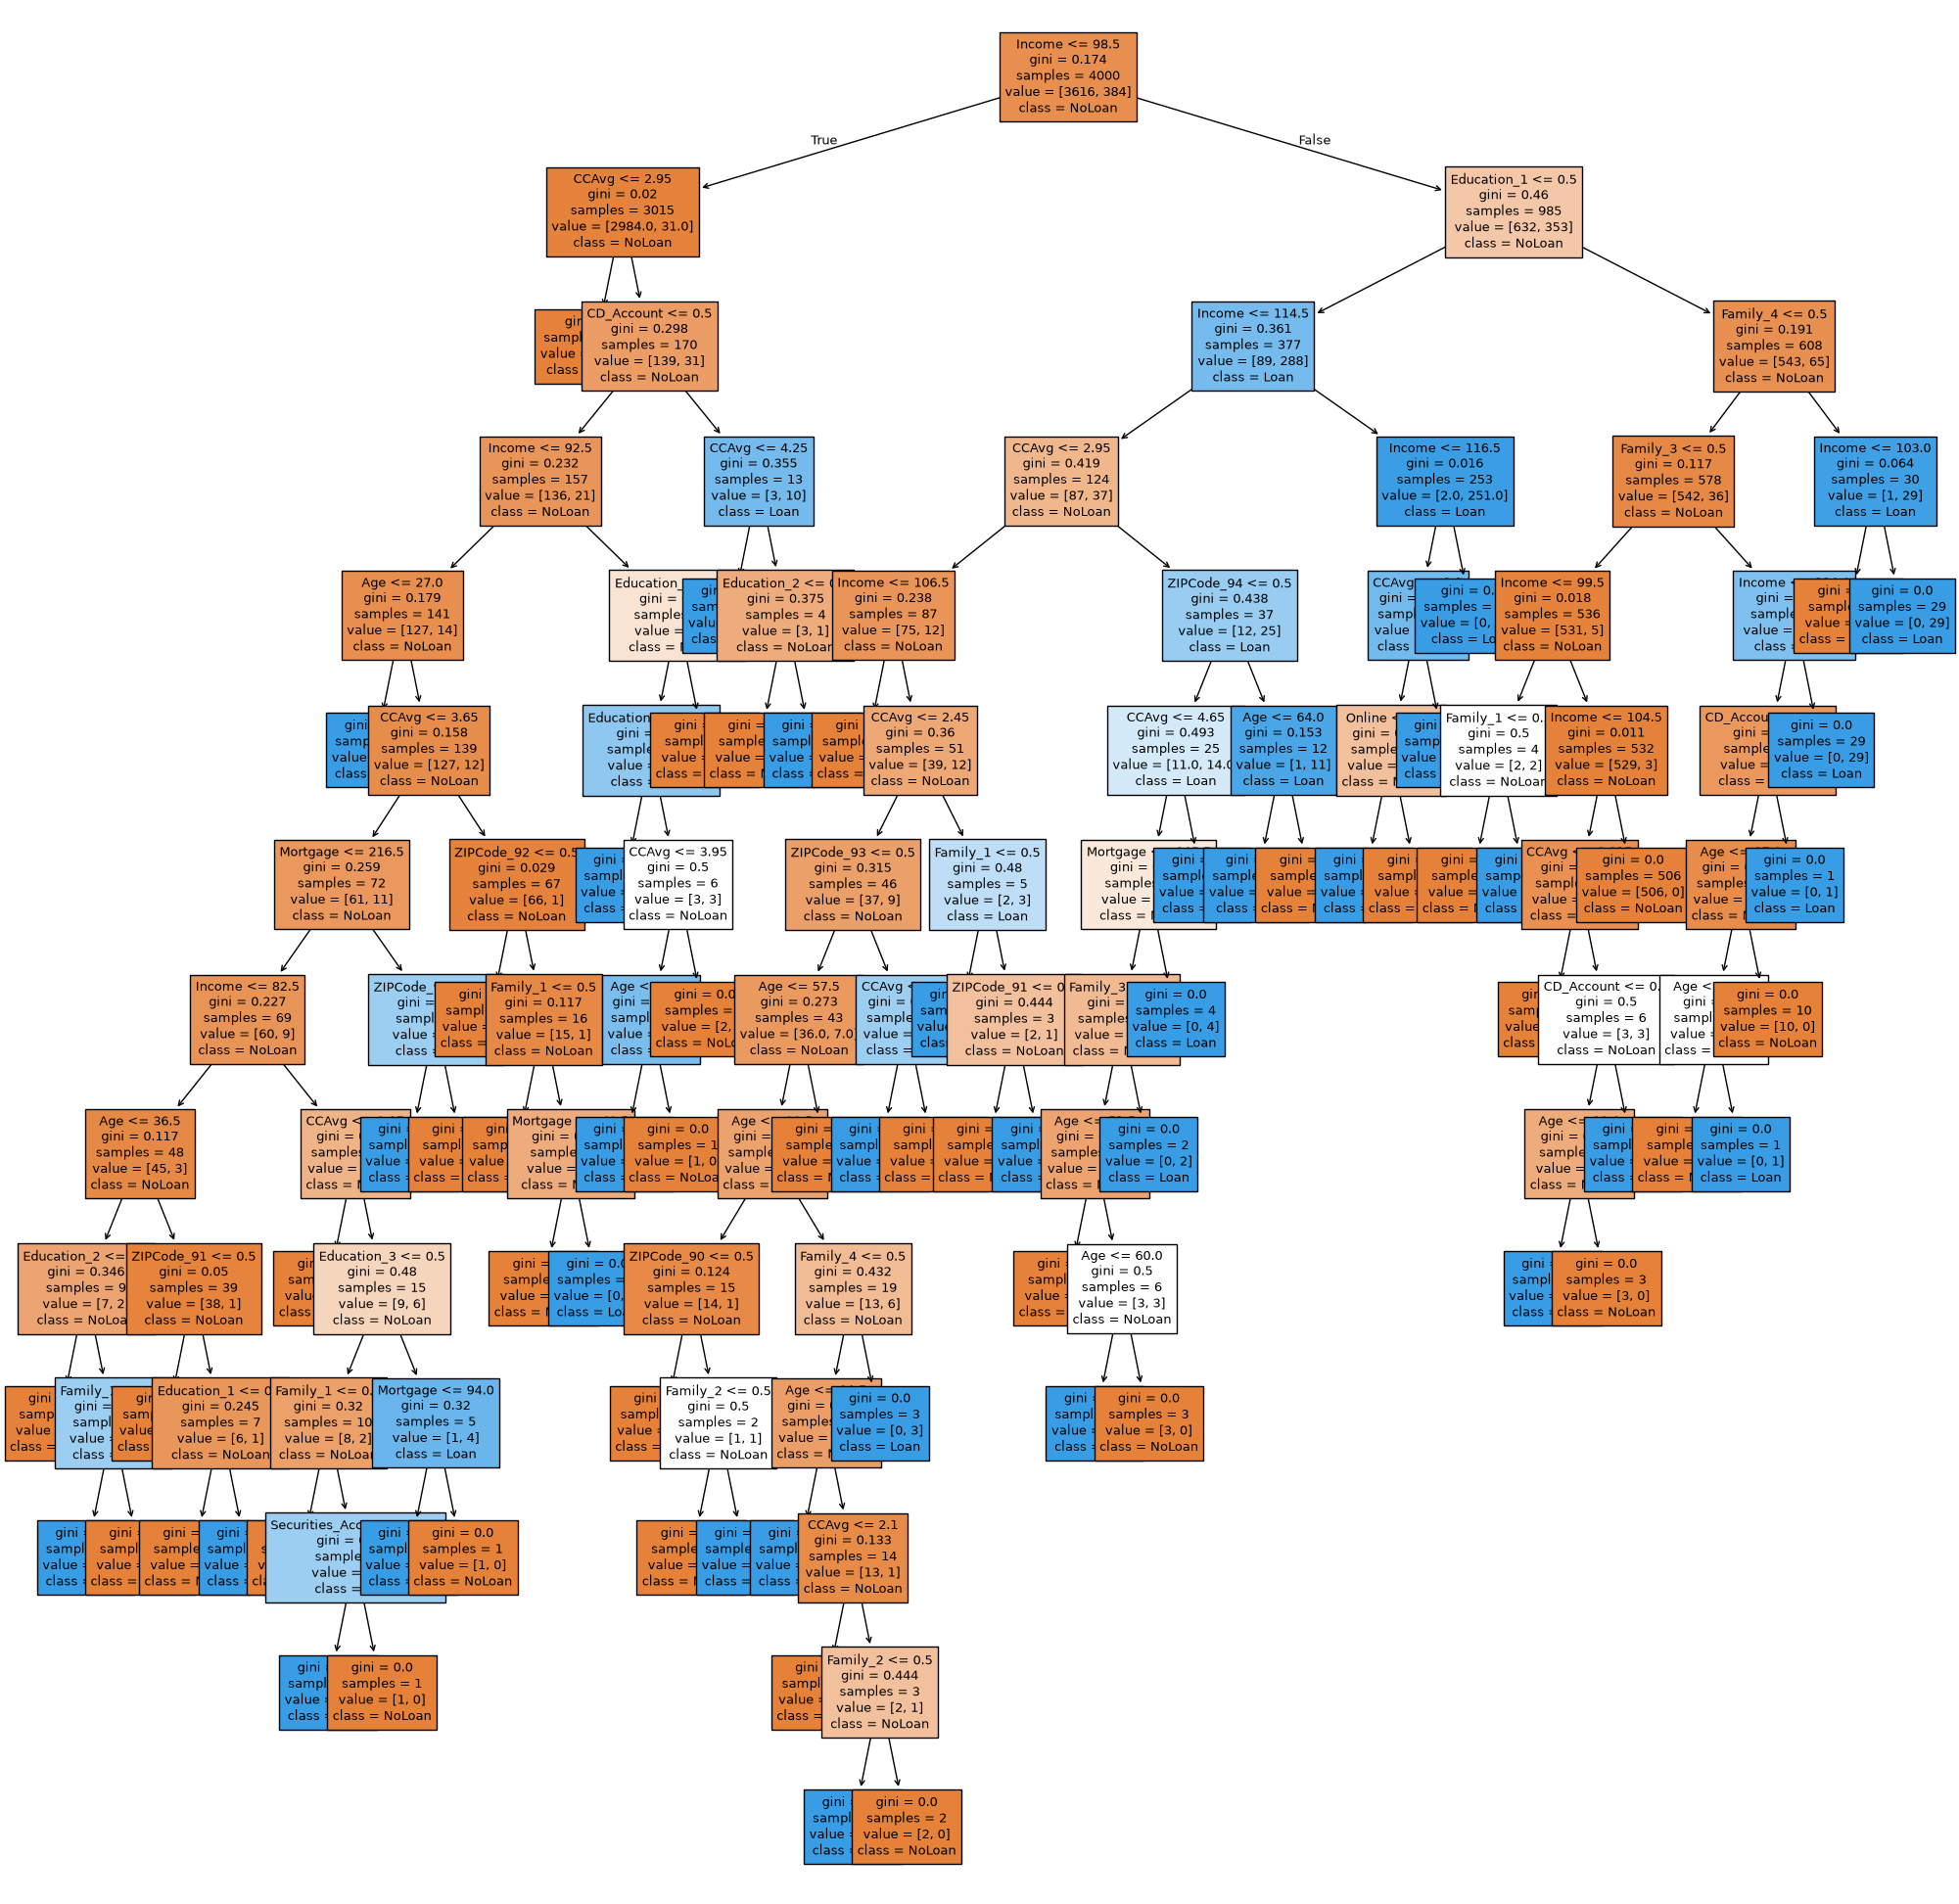

In [79]:
#Decision tree visulization
visualize_tree(model0, feature_names)

In [80]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model0, feature_names)

|--- Income <= 98.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [2845.00, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- Income <= 92.50
|   |   |   |   |--- Age <= 27.00
|   |   |   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |   |   |--- Age >  27.00
|   |   |   |   |   |--- CCAvg <= 3.65
|   |   |   |   |   |   |--- Mortgage <= 216.50
|   |   |   |   |   |   |   |--- Income <= 82.50
|   |   |   |   |   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [6.00, 0.00] class: 0
|   |   |   |   |   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |   |   |   |   |--- Family_1 <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |   |   |   |   |   |   |   |   |--- Family_1 >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [1.00, 0.00] class: 0
|   |   |   |   |   |   |   |

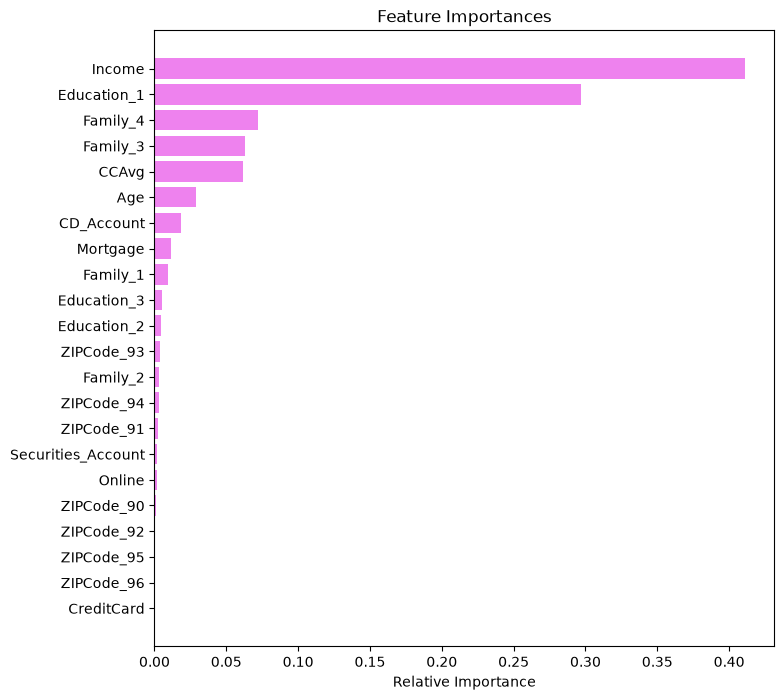

In [81]:
#Plotting feature importances
plot_feature_importances(model0, feature_names)

#### Model1 - Decision Tree (Scaled Data)

In [82]:
#Scaling data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [83]:
#Model on scaled data
model1 = DecisionTreeClassifier(criterion='gini', random_state=RS)
model1.fit(X_train_scaled, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [84]:
#Performance of the model on scaled train data
model1_train_perf = model_performance_classification(model1, X_train_scaled, y_train)
model1_train_perf

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


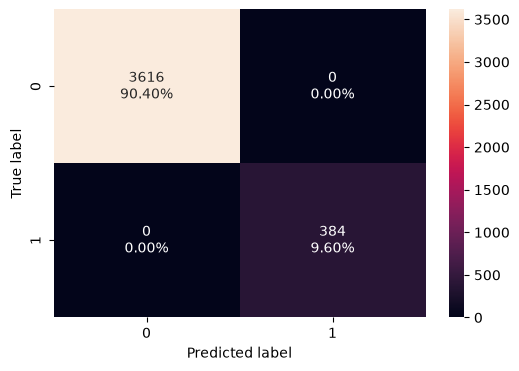

In [85]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model1, X_train_scaled, y_train)

In [86]:
#Performance of the model on scaled test data
model1_test_perf = model_performance_classification(model1, X_test_scaled, y_test)
model1_test_perf

,Accuracy,Recall,Precision,F1
0,0.986,0.947917,0.91,0.928571


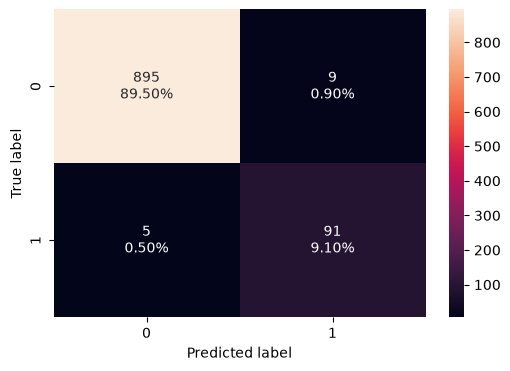

In [87]:
#Confusion Matrix of the basic model on test data
plot_confusion_matrix(model1, X_test_scaled, y_test)

Overall there are 14(9 FP + 5 FN) errors made by the model.

##### Feature names and importances

In [88]:
importances1 = model1.feature_importances_
indices1 = np.argsort(importances1)
importances1

array([2.86624238e-02, 4.10986753e-01, 6.16833350e-02, 1.12036517e-02,
       1.92047689e-03, 1.83614628e-02, 1.92047689e-03, 0.00000000e+00,
       2.97139067e-01, 4.72117236e-03, 5.18528761e-03, 9.56637552e-03,
       3.36083456e-03, 6.27008918e-02, 7.20014573e-02, 1.24830998e-03,
       2.25814316e-03, 1.37048957e-04, 3.97154233e-03, 2.97128918e-03,
       0.00000000e+00, 0.00000000e+00])

##### Visualization of the decision tree with scaled and balanced data

In [89]:
#Print Tree parameters
print_tree_parameters(model1)

Max depth: 13
Max leaf nodes: 69
Min samples split: 2


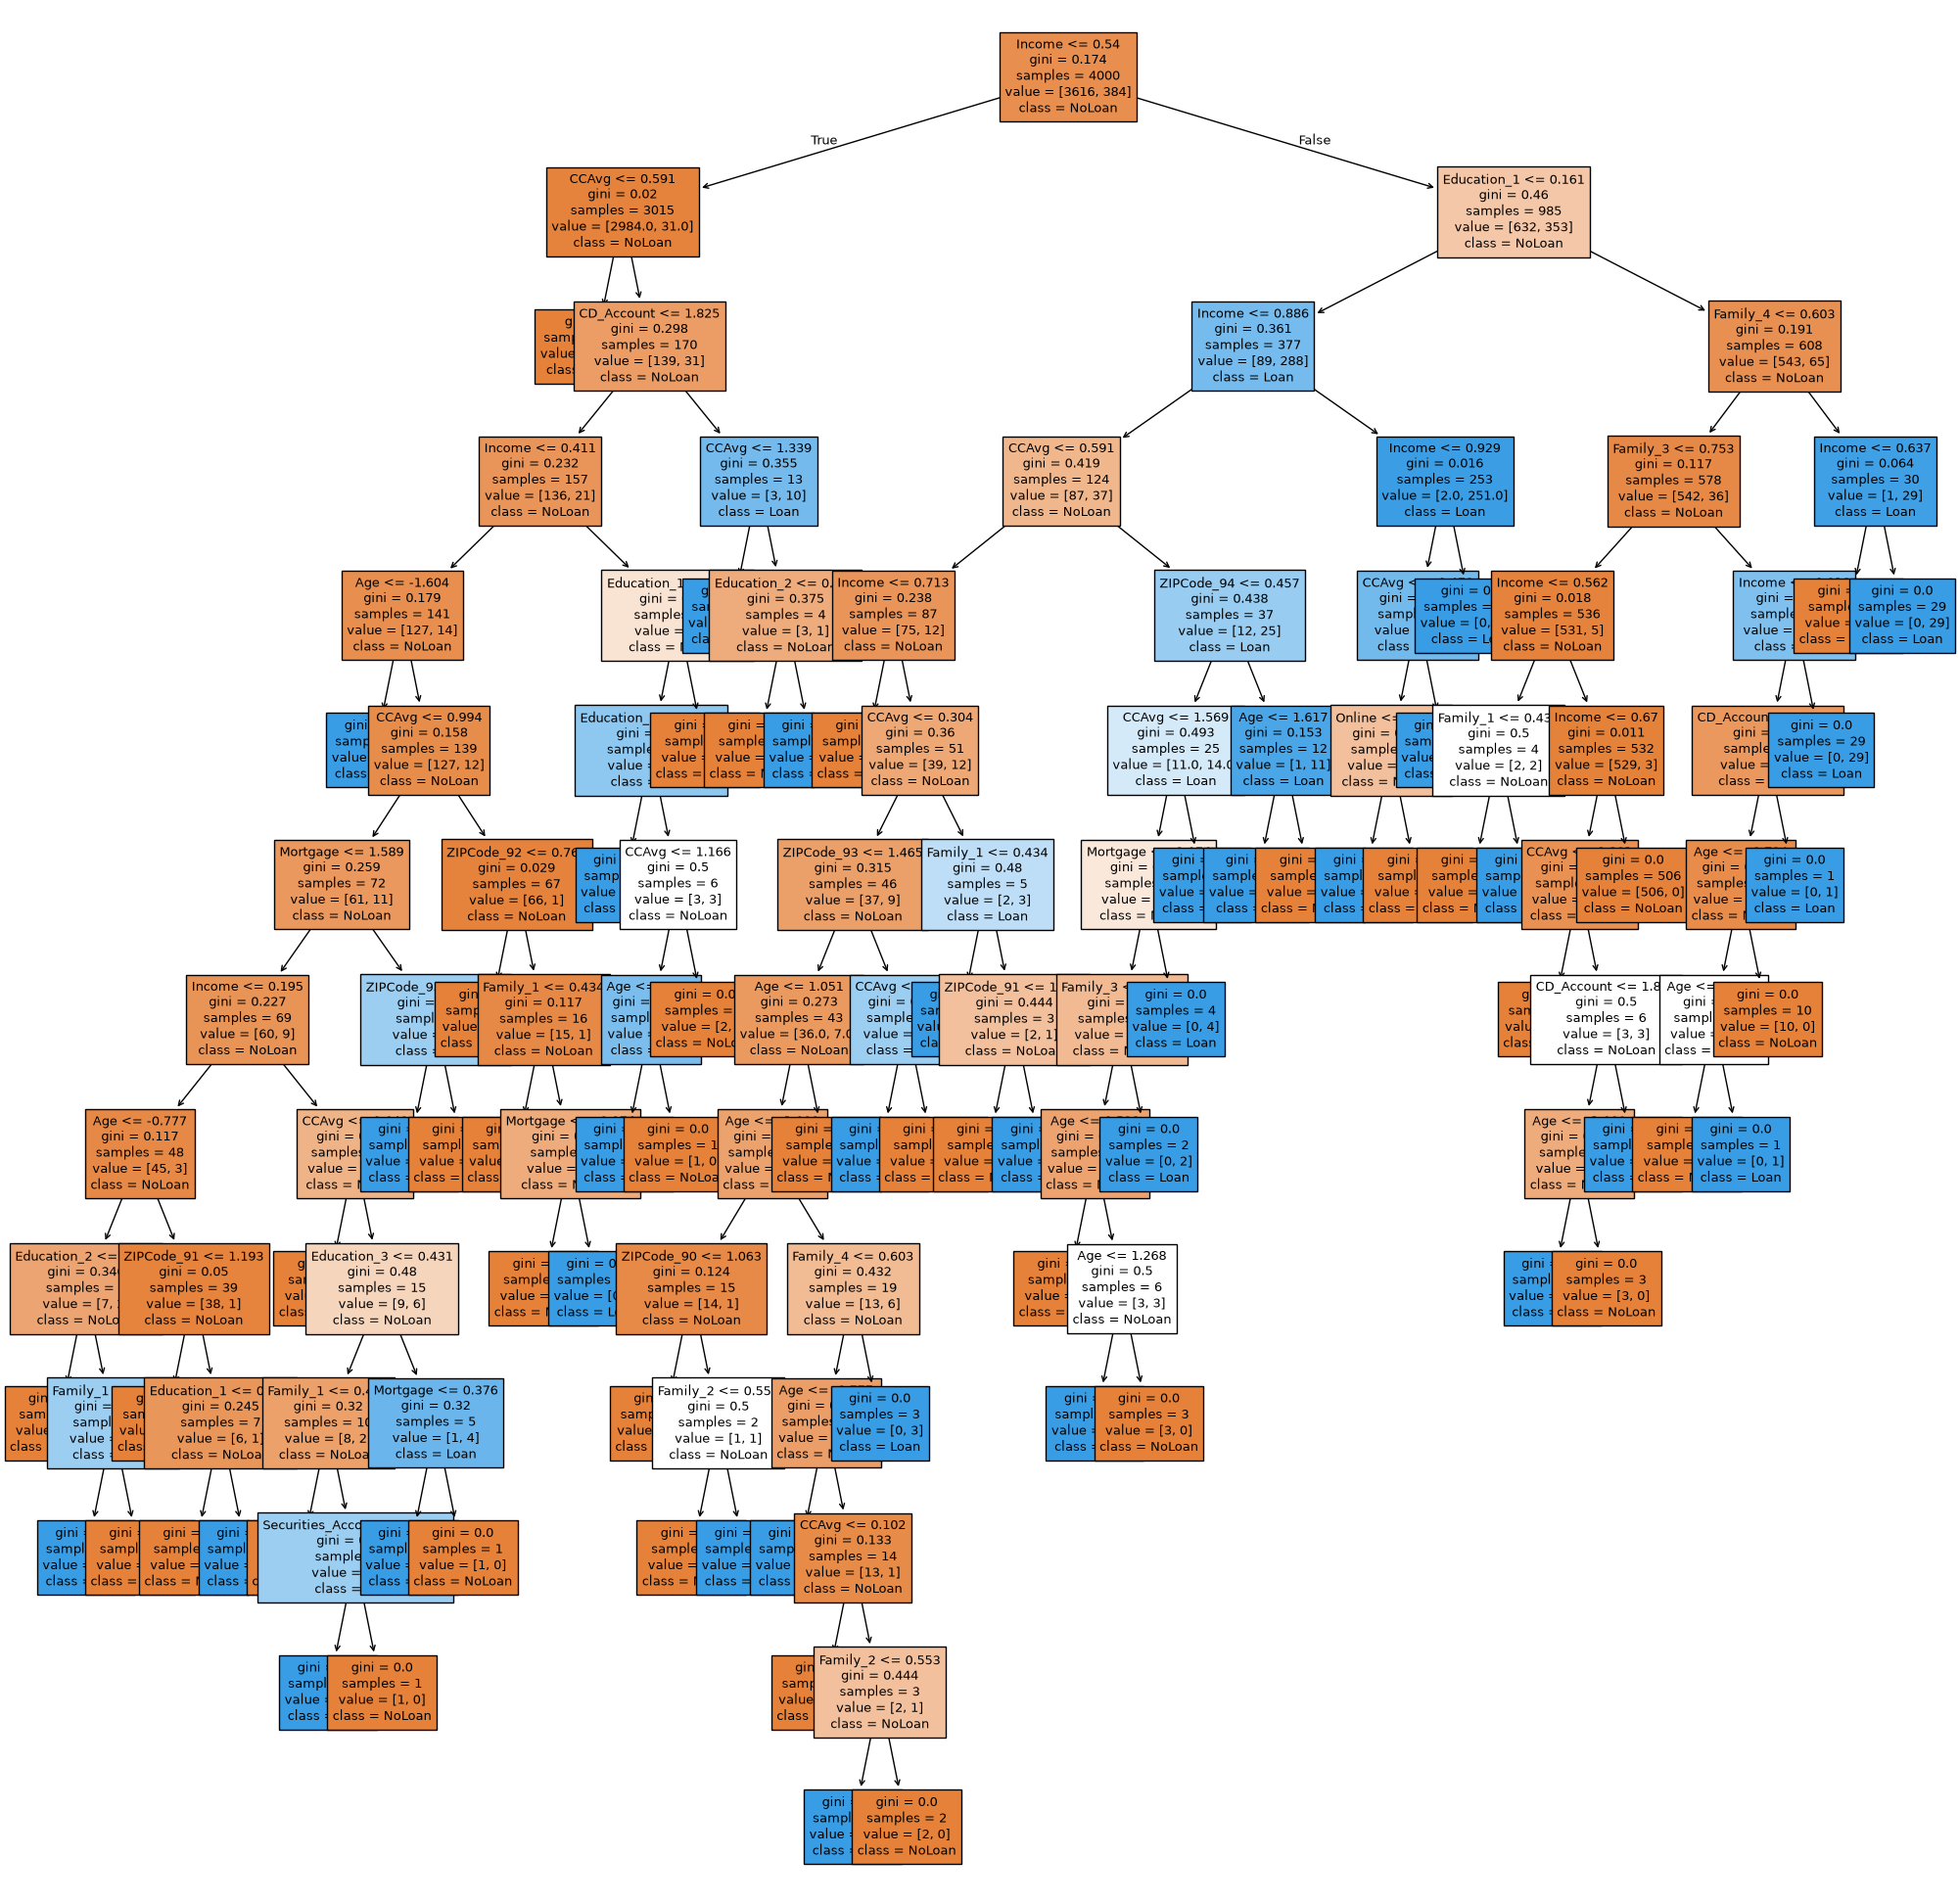

In [90]:
#Decision tree visulization
visualize_tree(model1, feature_names)

In [91]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model1, feature_names)

|--- Income <= 0.54
|   |--- CCAvg <= 0.59
|   |   |--- weights: [2845.00, 0.00] class: 0
|   |--- CCAvg >  0.59
|   |   |--- CD_Account <= 1.83
|   |   |   |--- Income <= 0.41
|   |   |   |   |--- Age <= -1.60
|   |   |   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |   |   |--- Age >  -1.60
|   |   |   |   |   |--- CCAvg <= 0.99
|   |   |   |   |   |   |--- Mortgage <= 1.59
|   |   |   |   |   |   |   |--- Income <= 0.19
|   |   |   |   |   |   |   |   |--- Age <= -0.78
|   |   |   |   |   |   |   |   |   |--- Education_2 <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [6.00, 0.00] class: 0
|   |   |   |   |   |   |   |   |   |--- Education_2 >  0.50
|   |   |   |   |   |   |   |   |   |   |--- Family_1 <= 0.43
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 2.00] class: 1
|   |   |   |   |   |   |   |   |   |   |--- Family_1 >  0.43
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [1.00, 0.00] class: 0
|   |   |   |   |   |   |   |   |-

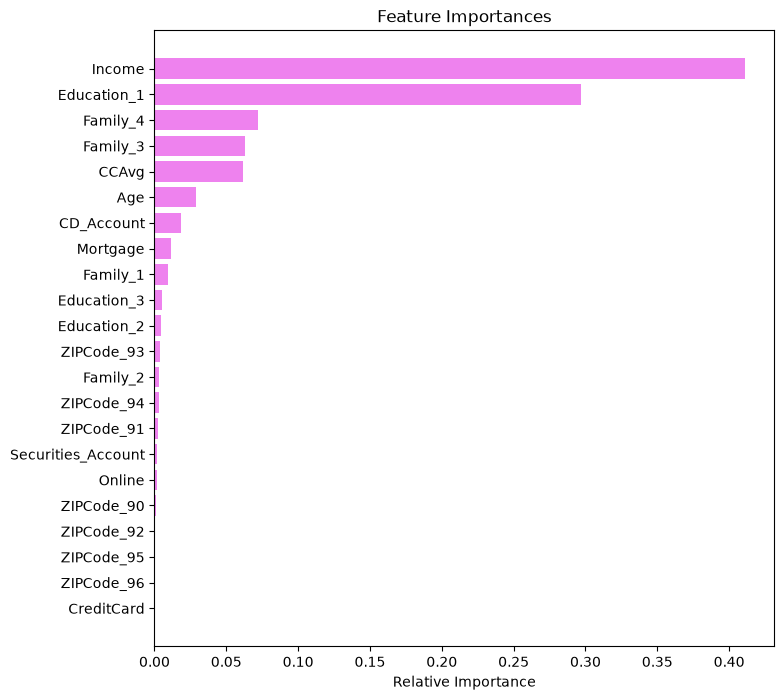

In [92]:
#Plotting feature importances
plot_feature_importances(model1, feature_names)


*   Scaling does not have any impact on the model

#### Model2 - Decision Tree (Class Weights)

In [93]:
#Model on scaled data
model2 = DecisionTreeClassifier(criterion='gini', random_state=RS, class_weight='balanced')
model2.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are 

In [94]:
#Performance of the model on scaled train data
model2_train_perf = model_performance_classification(model2, X_train, y_train)
model2_train_perf

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


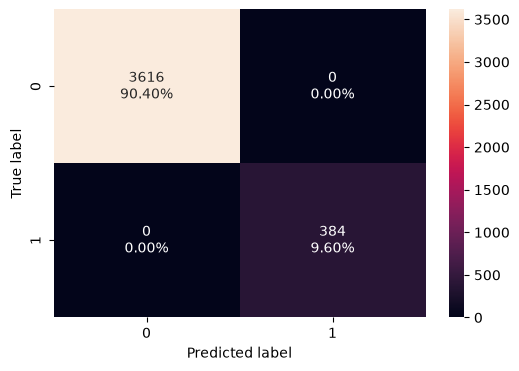

In [95]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model2, X_train, y_train)

In [96]:
#Performance of the model on scaled test data
model2_test_perf = model_performance_classification(model2, X_test, y_test)
model2_test_perf

,Accuracy,Recall,Precision,F1
0,0.982,0.947917,0.875,0.91


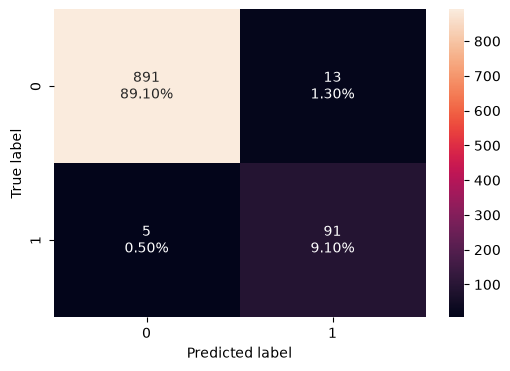

In [97]:
#Confusion Matrix of the basic model on test data
plot_confusion_matrix(model2, X_test, y_test)

Overall there are 19(14 FP + 5 FN) errors made by the model.

##### Feature names and importances

In [98]:
importances2 = model2.feature_importances_
indices2 = np.argsort(importances2)
importances2

array([2.02439311e-02, 6.31943146e-01, 9.51702217e-02, 6.16314048e-03,
       1.80985329e-03, 5.82862556e-03, 2.61657719e-03, 3.15676883e-04,
       9.06105268e-02, 0.00000000e+00, 3.67123981e-04, 8.21365045e-02,
       5.10924614e-02, 1.24651254e-03, 5.06975737e-03, 5.43478261e-04,
       0.00000000e+00, 2.04398391e-03, 5.41594454e-04, 1.96217964e-05,
       2.23726330e-03, 1.05741374e-16])

##### Visualization of the decision tree with scaled and balanced data

In [99]:
#Print Tree parameters
print_tree_parameters(model2)

Max depth: 17
Max leaf nodes: 85
Min samples split: 2


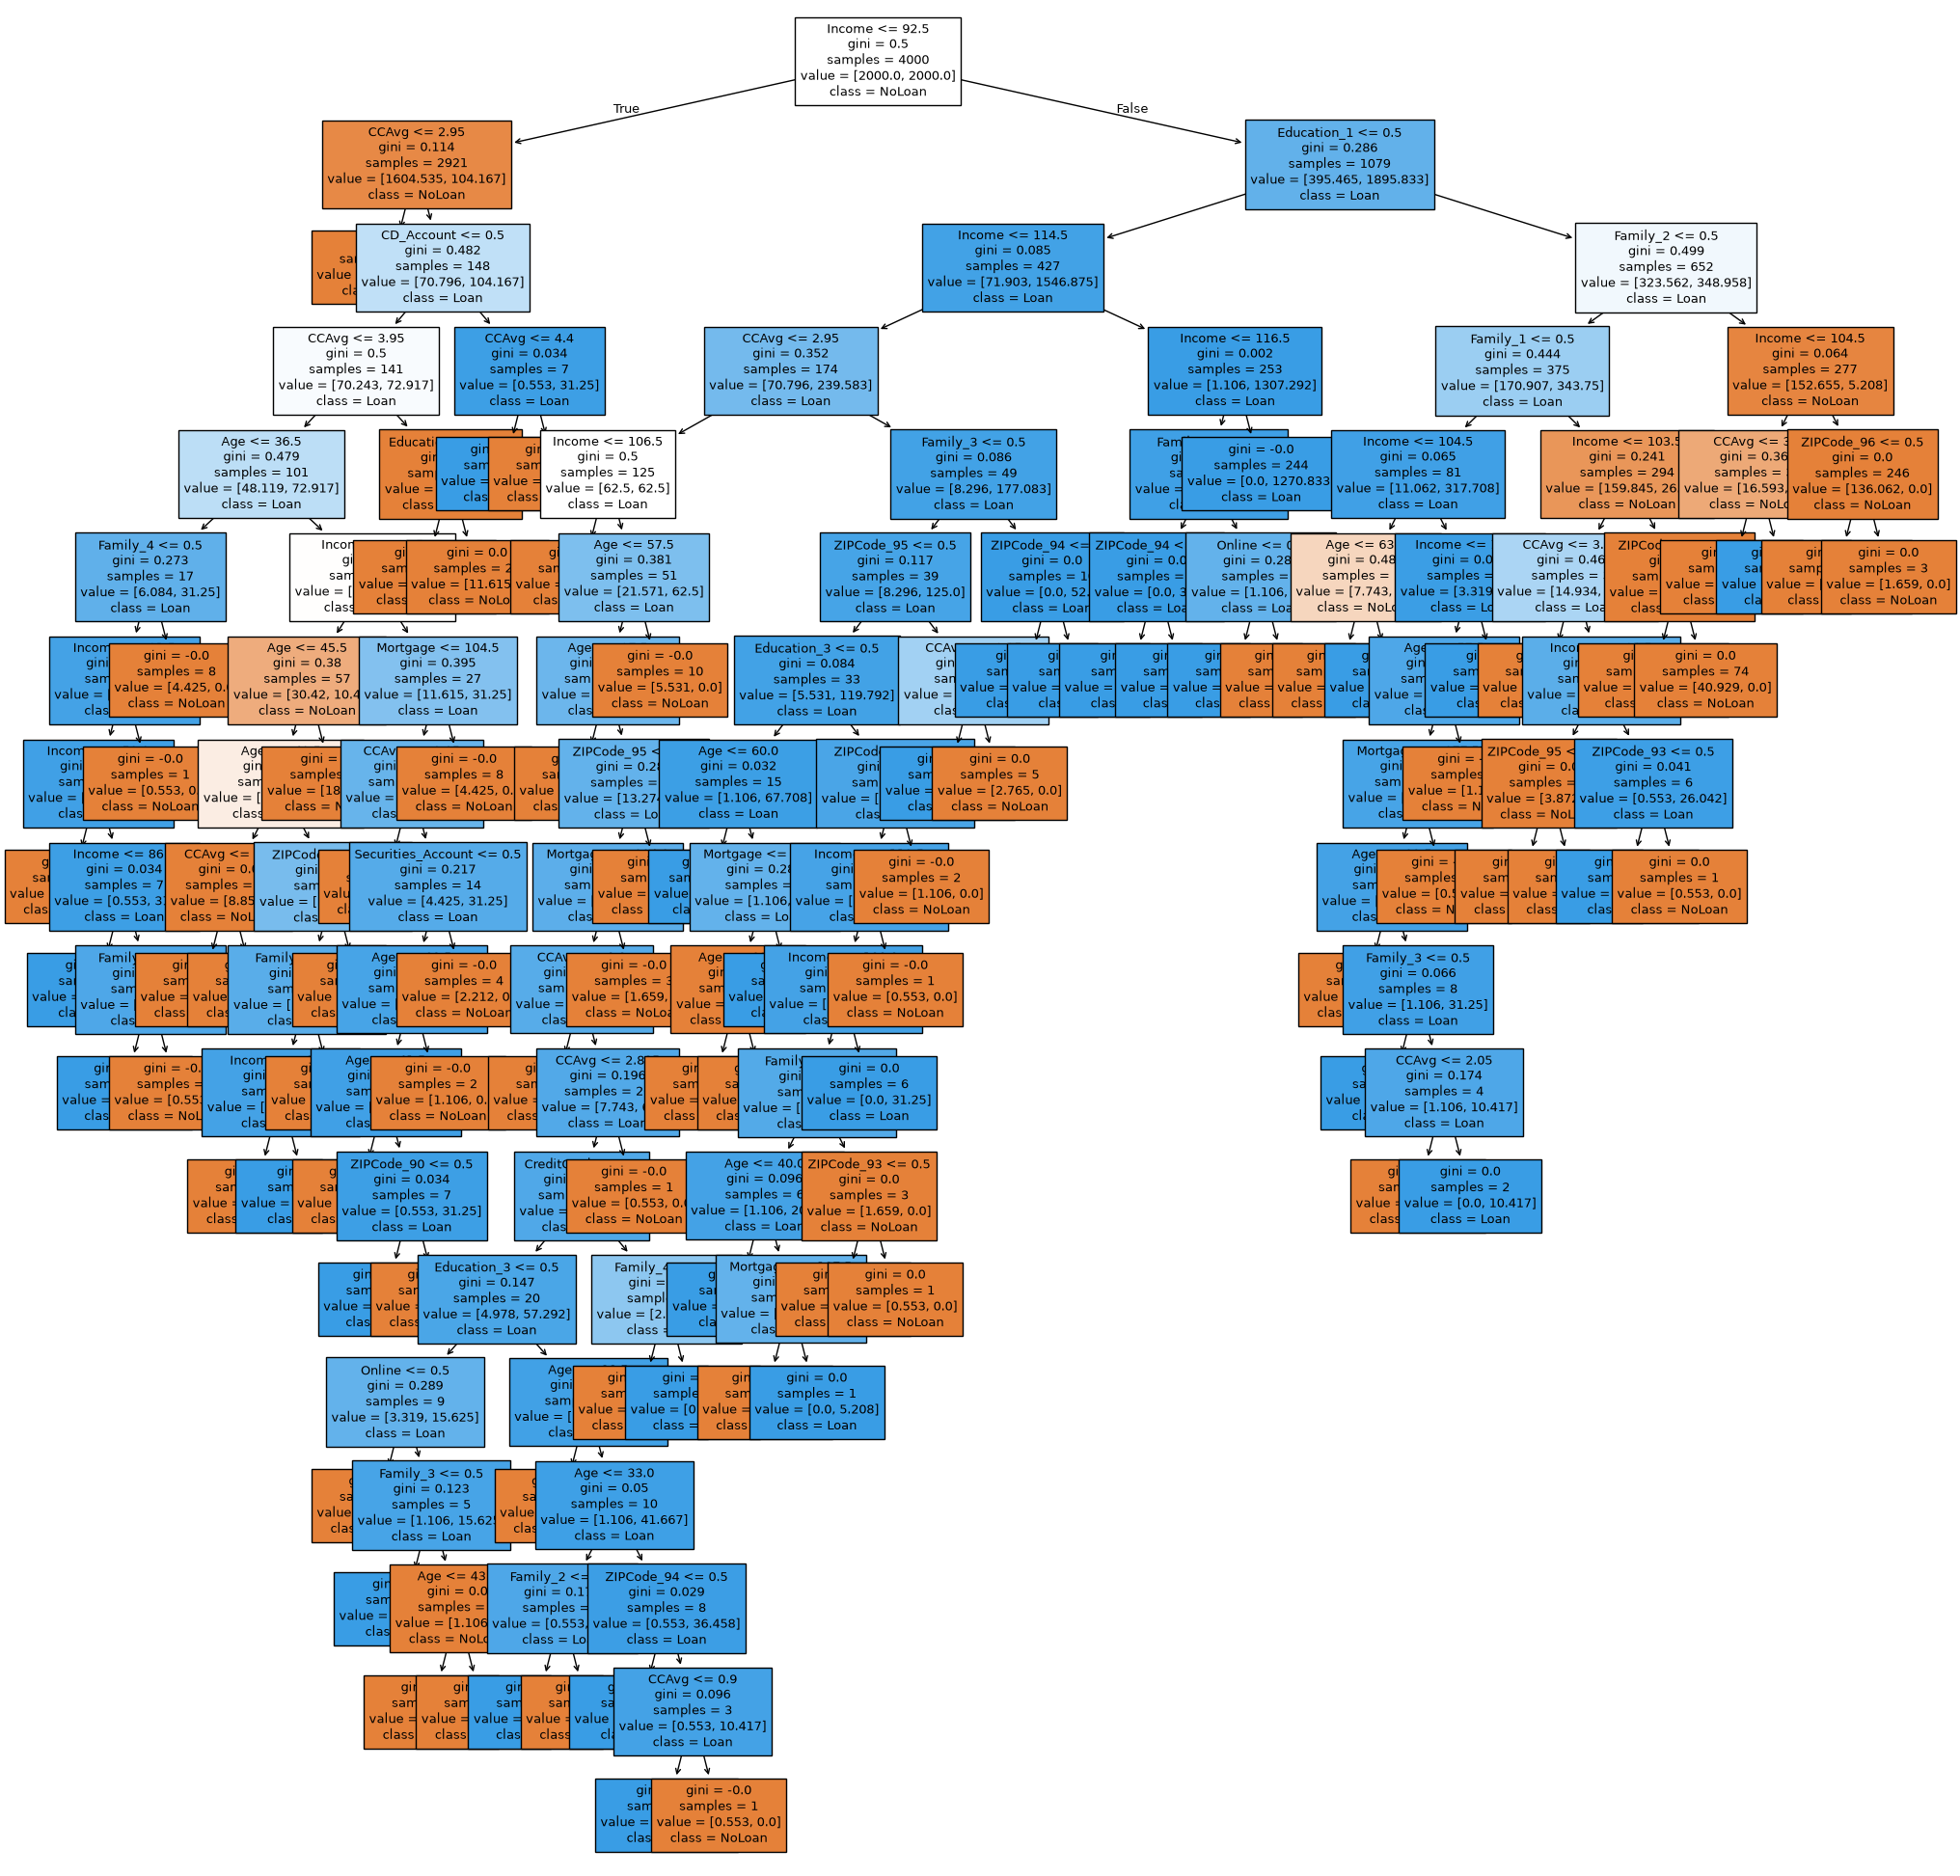

In [100]:
#Decision tree visulization
visualize_tree(model2, feature_names)

In [101]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model2, feature_names)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1533.74, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |--- Family_4 <= 0.50
|   |   |   |   |   |   |--- Income <= 91.50
|   |   |   |   |   |   |   |--- Income <= 59.00
|   |   |   |   |   |   |   |   |--- weights: [0.55, 0.00] class: 0
|   |   |   |   |   |   |   |--- Income >  59.00
|   |   |   |   |   |   |   |   |--- Income <= 86.50
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 26.04] class: 1
|   |   |   |   |   |   |   |   |--- Income >  86.50
|   |   |   |   |   |   |   |   |   |--- Family_2 <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 5.21] class: 1
|   |   |   |   |   |   |   |   |   |--- Family_2 >  0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.55, 0.00] class: 0
|   |   |   |   |   |   |--- Income >  91.50
|   |   |   |   |   |   |   |--- weights: [0

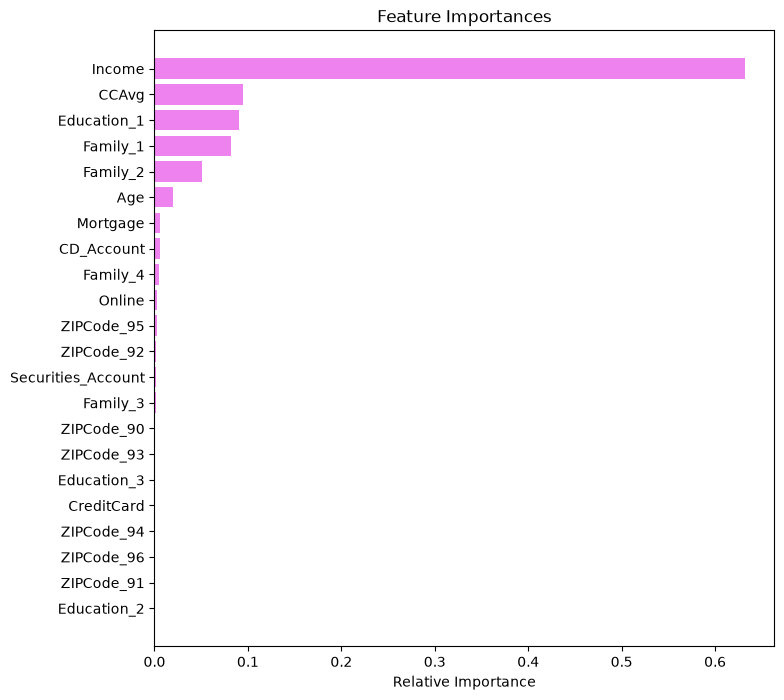

In [102]:
#Plotting feature importances
plot_feature_importances(model2, feature_names)

#### Observations on the model and model performance

There are two types of customers of this bank
*   liability customers (depositors)
*   asset customers (borrowers)

Objective:

*   Expand loan business
*   Identify potential liability customers that most likely take loan

Key terminalogy
*   Personal_Loan - 0 indicates not a loan purchaser
*   Personal_Loan - 1 indicates potential loan purchaser

Meaning of TP,TN,FP,FN in the context of the problem statement


*   TP - Model correctly predicts as a potential loan purchaser
*   FP - Model incorrectly predicts a customer as a loan purchaser

*   TN - Model correctly identifies as Not a potential loan purchaser
*   FN - Model prediction is as Not a potential loan purchaser, but in reality is an actual purchaser of a loan.

KPI:
*   FN is the most critical parameter for this analysis.
*   False Negative means Lost business opportunity to sell a loan
*   Hinders the loan business growth

*   Goal is to reduce False Negatives FN.
*   Recall (TP/(TP+FN)) is the most critical evaluation parameter.


## Model Performance Improvement

### Model3 - Pre-Pruning

In [103]:
# Define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 21, 2)
max_leaf_nodes_values = np.arange(10, 101, 10)
min_samples_split_values = np.arange(5, 51, 10)

# Initialize variables to store the best model and its performance
best_estimator = None
best_score_diff = float('inf')
best_test_score = 0.0

# Iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # Initialize the tree with the current set of parameters
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                class_weight='balanced',
                random_state=RS
            )

            # Fit the model to the training data
            estimator.fit(X_train, y_train)

            # Make predictions on the training and test sets
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # Calculate recall scores for training and test sets
            train_recall_score = recall_score(y_train, y_train_pred)
            test_recall_score = recall_score(y_test, y_test_pred)

            # Calculate the absolute difference between training and test recall scores
            score_diff = abs(train_recall_score - test_recall_score)

            # Update the best estimator and best score if the current one has a smaller score difference
            if (score_diff < best_score_diff) & (test_recall_score > best_test_score):
                best_score_diff = score_diff
                best_test_score = test_recall_score
                best_estimator = estimator

# Print the best parameters
print("Best parameters From pre-pruning :")
print(f"Max depth: {best_estimator.max_depth}")
print(f"Max leaf nodes: {best_estimator.max_leaf_nodes}")
print(f"Min samples split: {best_estimator.min_samples_split}")
print(f"Best test recall score: {best_test_score}")

Best parameters From pre-pruning :
Max depth: 2
Max leaf nodes: 10
Min samples split: 5
Best test recall score: 1.0


#### Best Model Based on Pre-Pruning

In [104]:
#Creating the best model based on Pre-Pruning
model3 = best_estimator# creating the model where we get highest train and test recall
model3.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(2)
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",np.int64(5)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",np.int64(10)
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=

In [105]:
#Performance of the model on scaled train data
model3_train_perf = model_performance_classification(model3, X_train, y_train)
model3_train_perf

,Accuracy,Recall,Precision,F1
0,0.78925,1.0,0.312958,0.476723


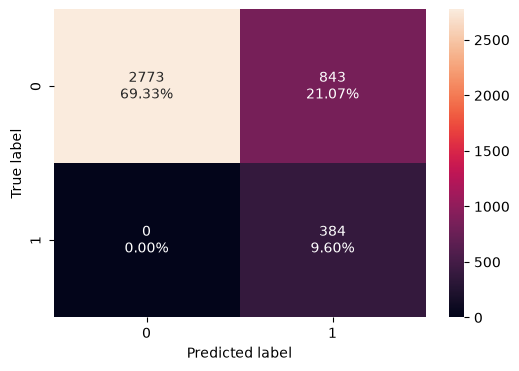

In [106]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model3, X_train, y_train)

In [107]:
#Performance of the model on scaled test data
model3_test_perf = model_performance_classification(model3, X_test, y_test)
model3_test_perf

,Accuracy,Recall,Precision,F1
0,0.778,1.0,0.301887,0.463768


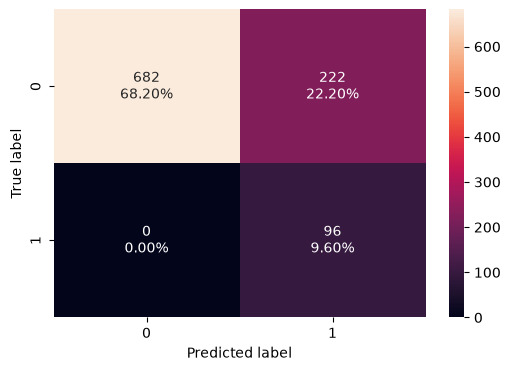

In [108]:
#Confusion Matrix of the model on test data
plot_confusion_matrix(model3, X_test, y_test)

Overall there are 222(222 FP + 0 FN) errors made by the model.

#### Feature names and importances

In [109]:
importances3 = model3.feature_importances_
indices3 = np.argsort(importances3)
importances3

array([0.        , 0.7971895 , 0.07718085, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.12562964, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        ])

#### Visualization of the best decision tree based on Pre-Pruning

In [110]:
#Print Tree parameters
print_tree_parameters(model3)

Max depth: 2
Max leaf nodes: 4
Min samples split: 5


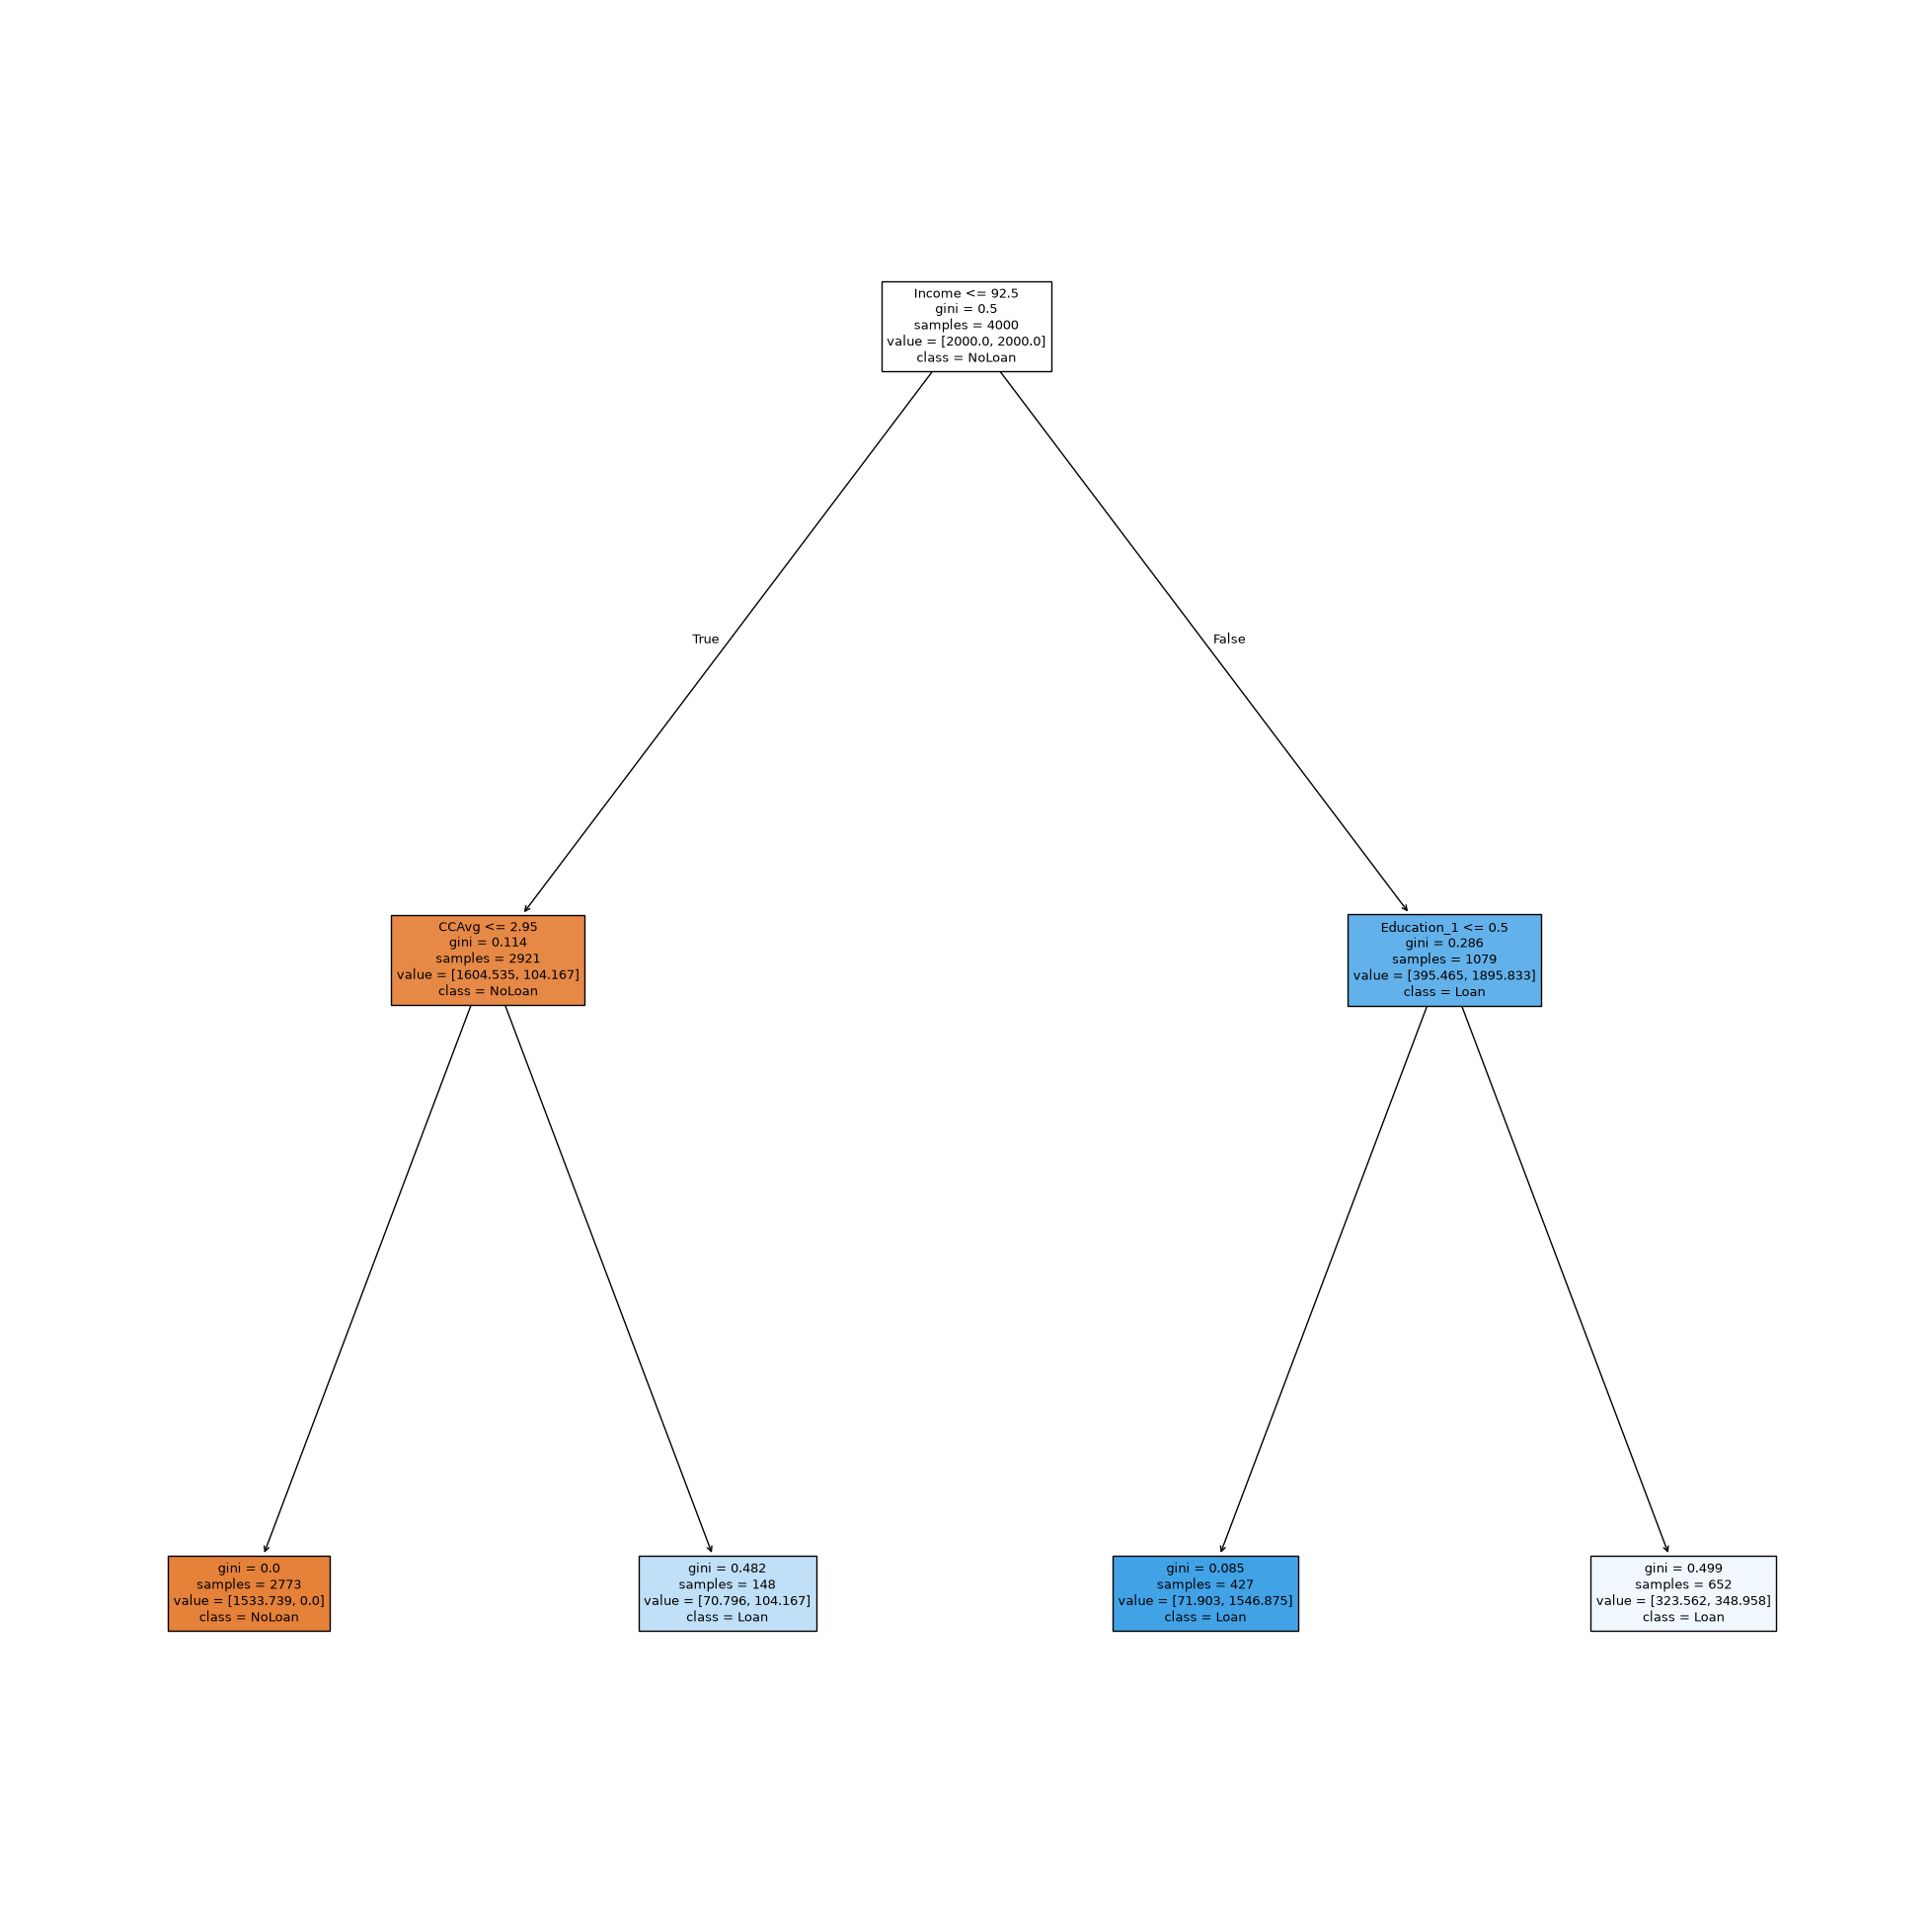

In [111]:
#Decision tree visulization
visualize_tree(model3, feature_names)

In [112]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model3, feature_names)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1533.74, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- weights: [70.80, 104.17] class: 1
|--- Income >  92.50
|   |--- Education_1 <= 0.50
|   |   |--- weights: [71.90, 1546.87] class: 1
|   |--- Education_1 >  0.50
|   |   |--- weights: [323.56, 348.96] class: 1



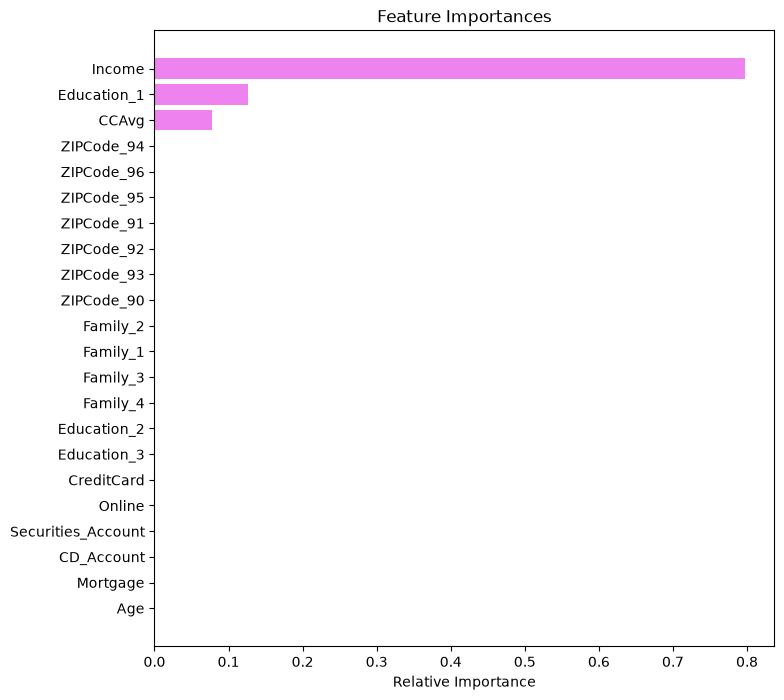

In [113]:
#Plotting feature importances
plot_feature_importances(model3, feature_names)

Pre-pruned Model is overly simplified and not able to capture the important structure and patterns in the data.

### Model4 - Post-Pruning

In [114]:
clf = DecisionTreeClassifier(random_state=RS, class_weight={0:0.1,1:0.9})
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = abs(path.ccp_alphas), path.impurities

In [115]:
#ccp_alpha values and their corresponding impurities
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000e+00,-7.962459e-17
1,1.569885e-19,-7.946760e-17
2,1.569885e-19,-7.931062e-17
3,1.569885e-19,-7.915363e-17
4,4.395679e-19,-7.871406e-17
5,5.651588e-19,-7.814890e-17
6,9.890279e-19,-7.715987e-17
7,9.890279e-19,-7.617084e-17
8,2.119345e-18,-7.405150e-17
9,3.076976e-18,-7.097452e-17


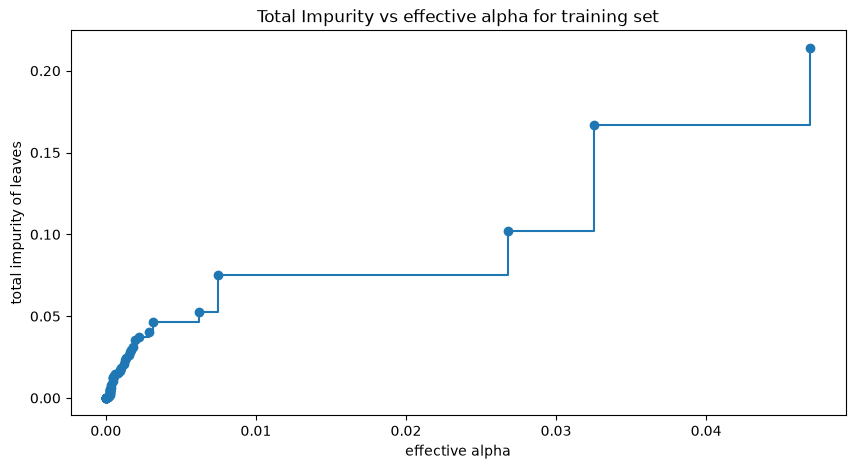

In [116]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set")
plt.show()

In [117]:
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(
        random_state=RS, ccp_alpha=ccp_alpha, class_weight="balanced"
    )
    clf.fit(X_train, y_train)
    clfs.append(clf)
print(
    "Number of nodes in the last tree is: {} with ccp_alpha: {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is: 3 with ccp_alpha: 0.2858330179234302


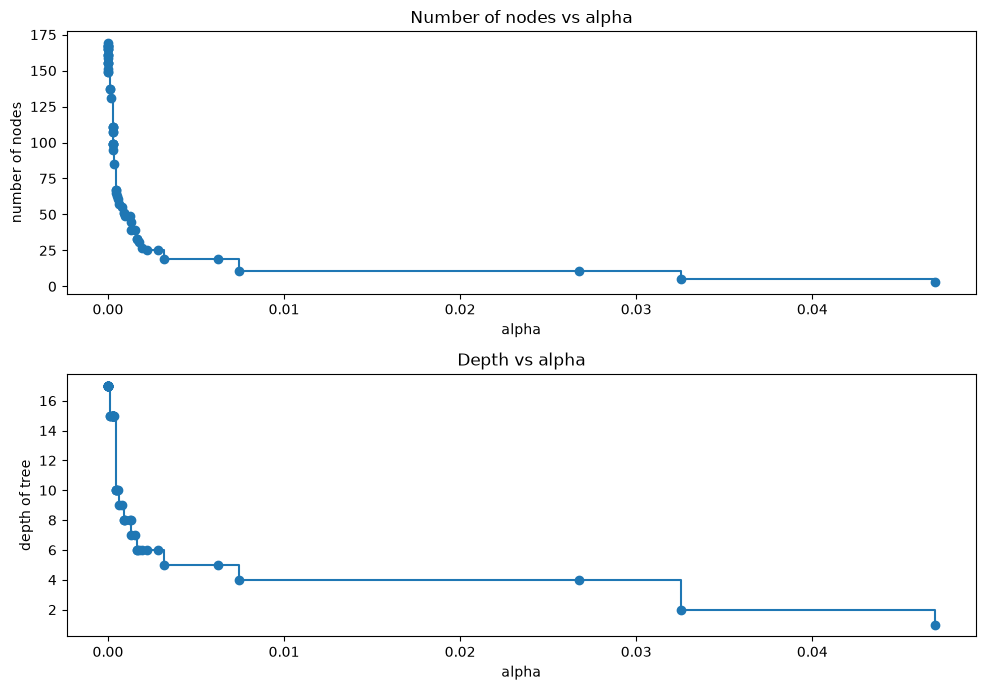

In [118]:
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

node_counts = [clf.tree_.node_count for clf in clfs]
depth = [clf.tree_.max_depth for clf in clfs]
fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

In [119]:
#Training Recall scores of the post pruned models
recall_train = []
for clf in clfs:
    pred_train = clf.predict(X_train)
    values_train = recall_score(y_train, pred_train)
    recall_train.append(values_train)

In [120]:
#Test data Recal scores of the post pruned model
recall_test = []
for clf in clfs:
    pred_test = clf.predict(X_test)
    values_test = recall_score(y_test, pred_test)
    recall_test.append(values_test)

In [121]:
train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]

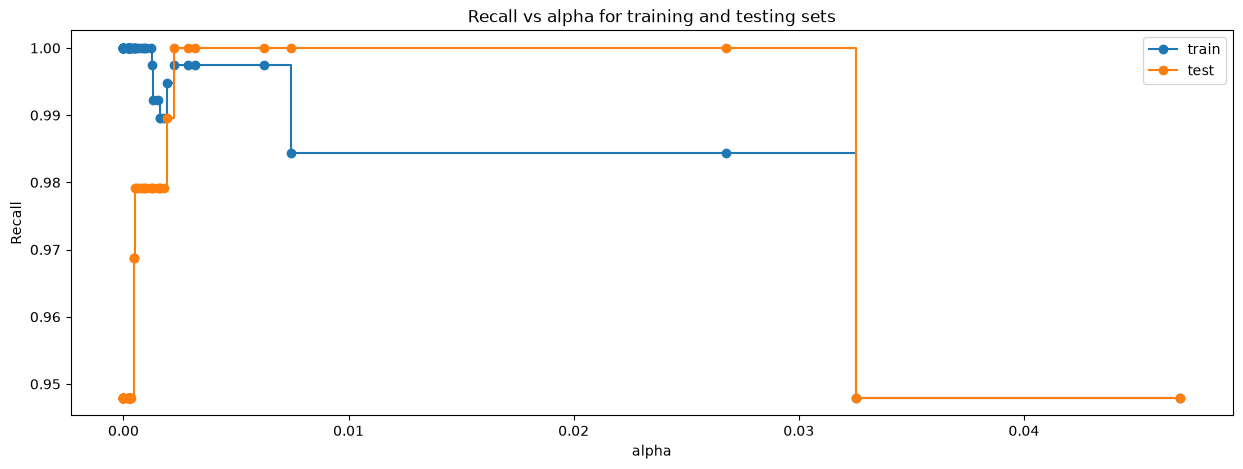

In [122]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel("alpha")
ax.set_ylabel("Recall")
ax.set_title("Recall vs alpha for training and testing sets")
ax.plot(
    ccp_alphas, recall_train, marker="o", label="train", drawstyle="steps-post",
)
ax.plot(ccp_alphas, recall_test, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

Test score is better than the Train score for the most alpha values

#### Best Model Based on Post-Pruning

In [123]:
# creating the model where we get highest train and test recall
index_best_model = np.argmax(recall_test)
best_model = clfs[index_best_model]
print(best_model)

DecisionTreeClassifier(ccp_alpha=np.float64(0.002229831871791061),
                       class_weight='balanced', random_state=42)


In [124]:
#Creating the best model based on Post-Pruning
model4 = best_model# creating the model where we get highest train and test recall
model4.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"ccp_alpha ccp_alpha: non-negative float, default=0.0Complexity parameter used for Minimal Cost-Complexity Pruning. Thesubtree with the largest cost complexity that is smaller than``ccp_alpha`` will be chosen. By default, no pruning is performed. See:ref:`minimal_cost_complexity_pruning` for details. See:ref:`sphx_glr_auto_examples_tree_plot_cost_complexity_pruning.py`for an example of such pruning... versionadded:: 0.22",np.float64(0....9831871791061)
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the 

In [125]:
#Performance of the model on scaled train data
model4_train_perf = model_performance_classification(model4, X_train, y_train)
model4_train_perf

,Accuracy,Recall,Precision,F1
0,0.95675,0.997396,0.69009,0.815761


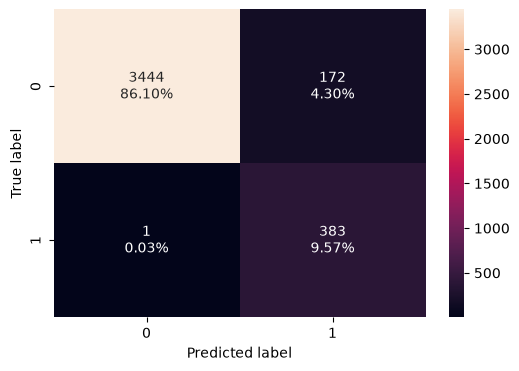

In [126]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model4, X_train, y_train)

Model predicted 172 False Positives and 1 False Negative.

In [127]:
#Performance of the model on scaled test data
model4_test_perf = model_performance_classification(model4, X_test, y_test)
model4_test_perf

,Accuracy,Recall,Precision,F1
0,0.95,1.0,0.657534,0.793388


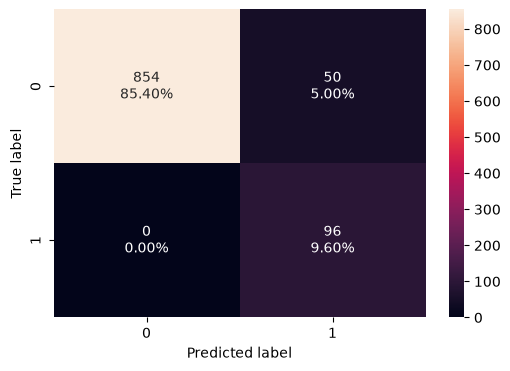

In [128]:
#Confusion Matrix of the basic model on test data
plot_confusion_matrix(model4, X_test, y_test)

#### Feature names and importances

In [129]:
importances4 = model4.feature_importances_
indices4 = np.argsort(importances4)
importances4

array([0.        , 0.66535326, 0.09033132, 0.        , 0.        ,
       0.00629514, 0.        , 0.        , 0.0978629 , 0.        ,
       0.        , 0.0875579 , 0.05259949, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        ])

#### Visualization of the best decision tree based on Pre-Pruning

In [130]:
#Print Tree parameters
print_tree_parameters(model4)

Max depth: 6
Max leaf nodes: 13
Min samples split: 2


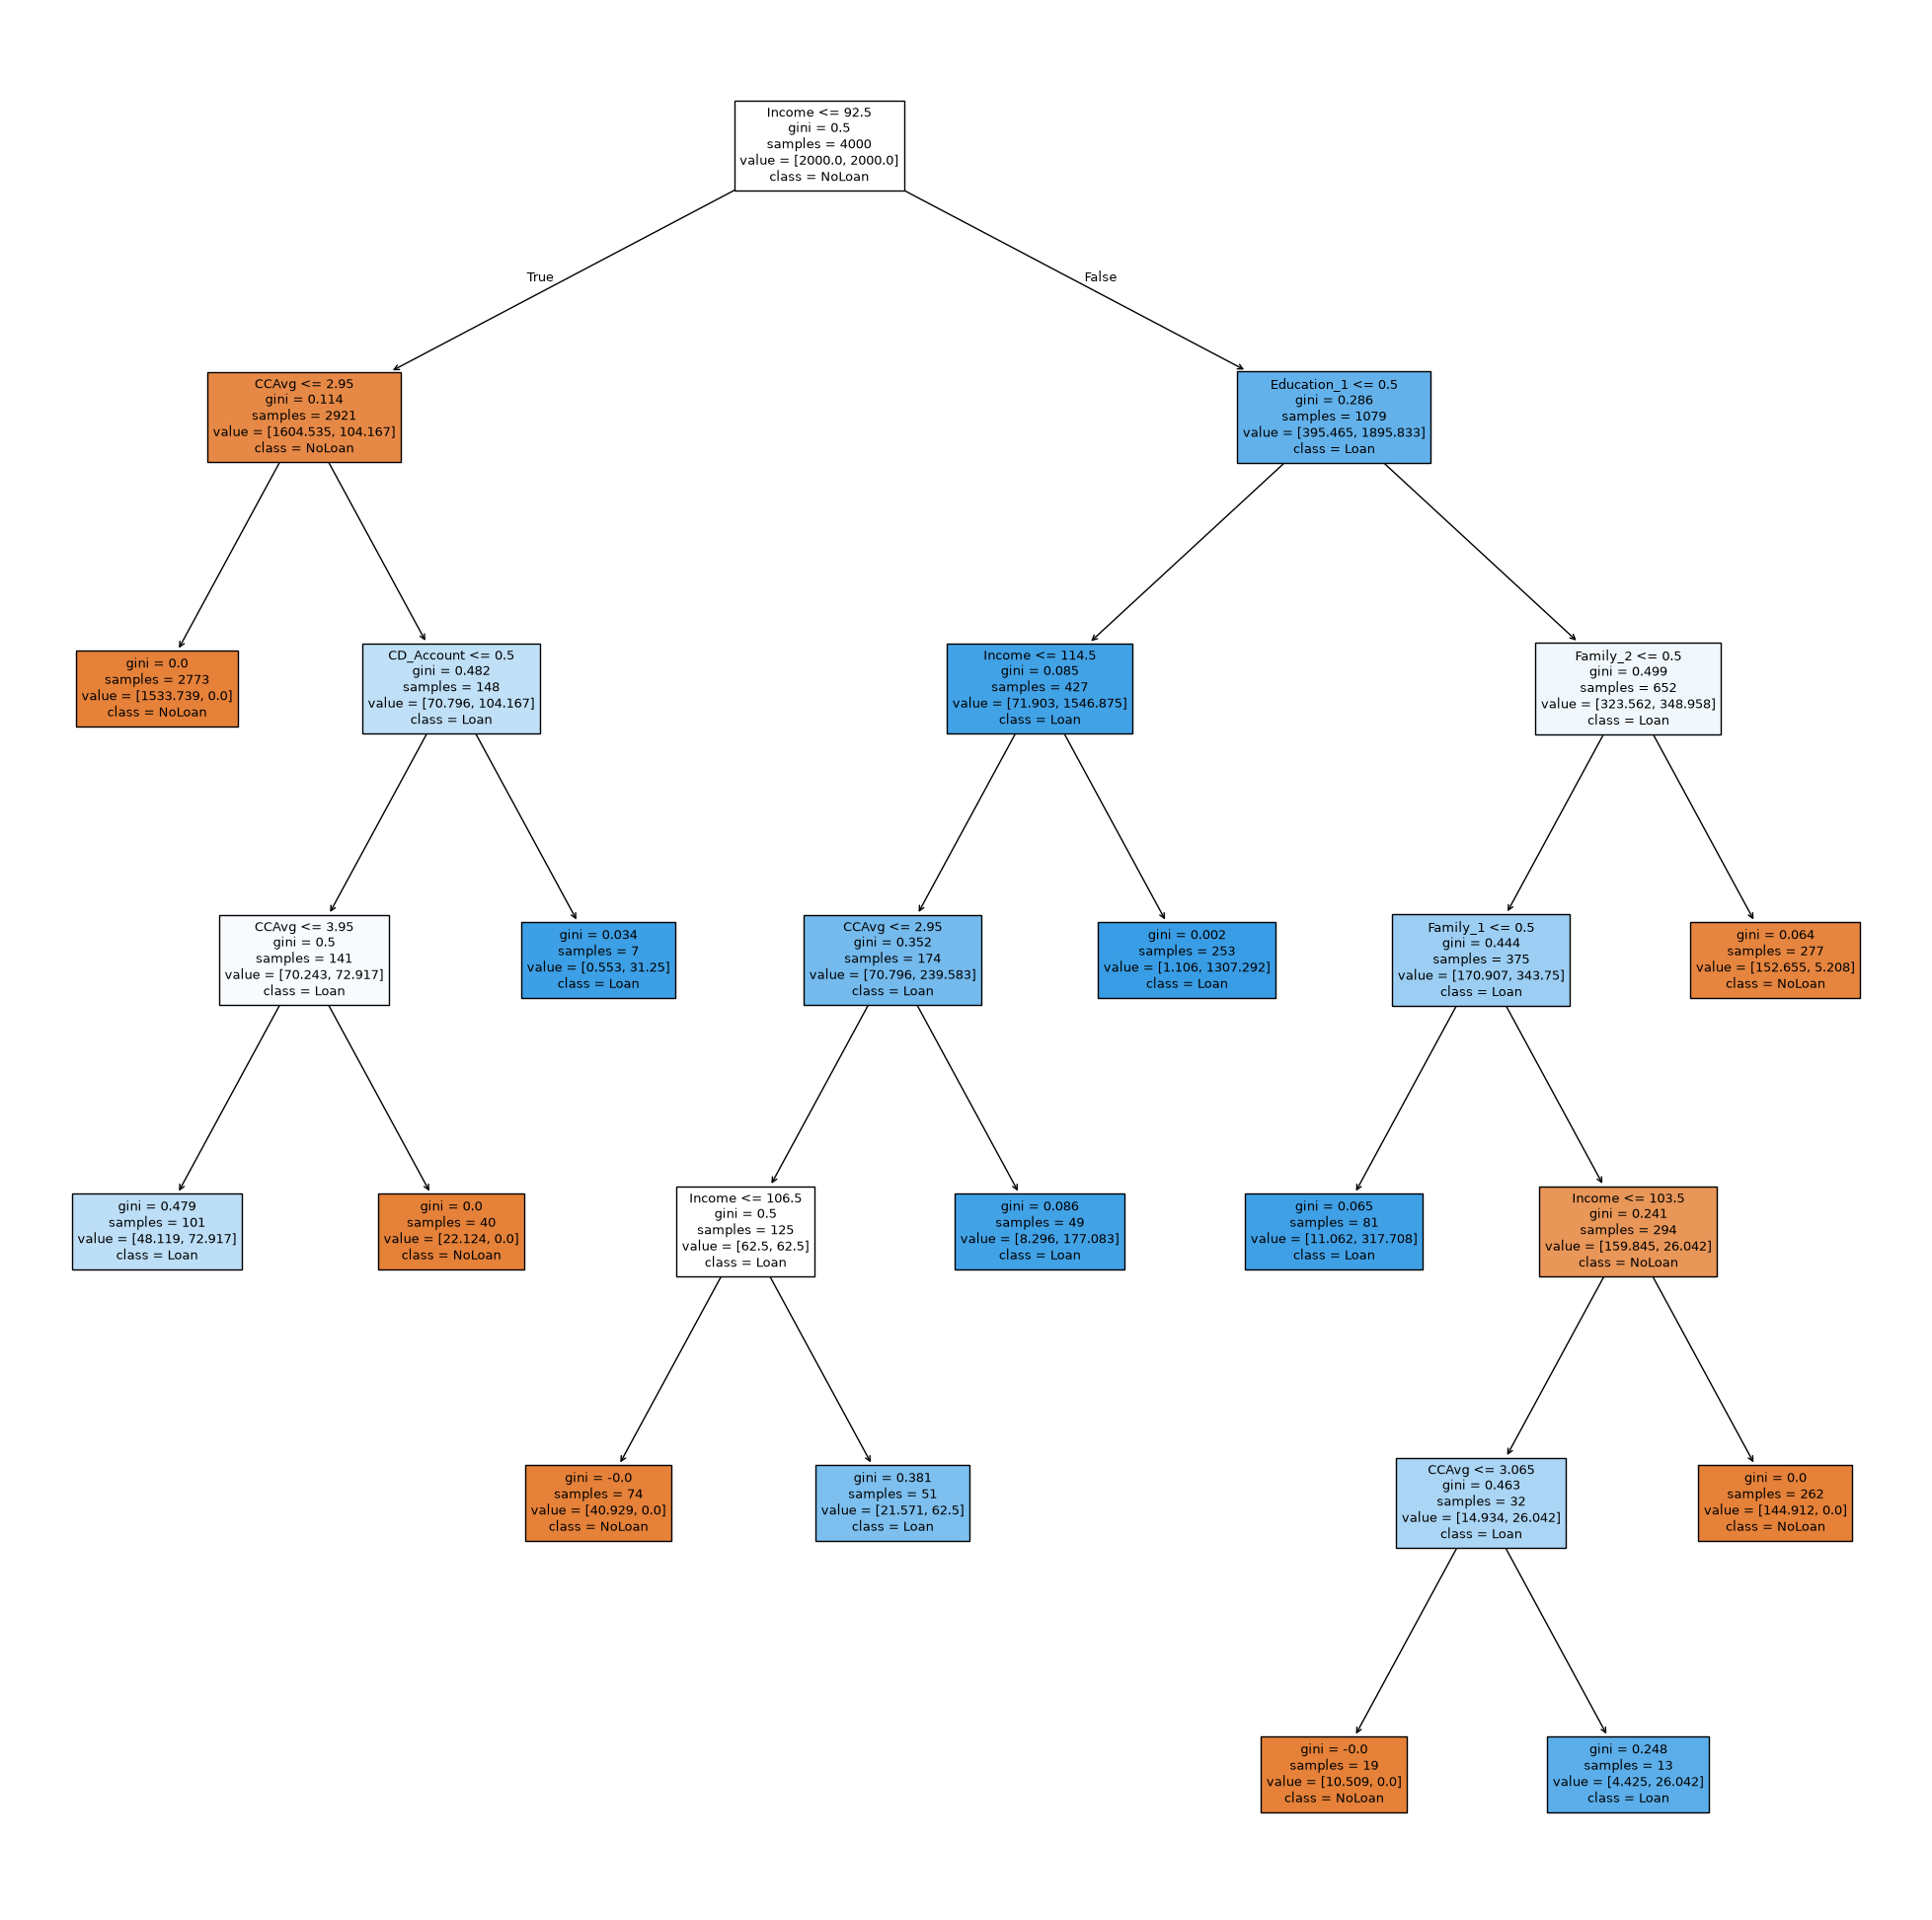

In [131]:
#Decision tree visulization
visualize_tree(model4, feature_names)

In [132]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model4, feature_names)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- weights: [1533.74, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- weights: [48.12, 72.92] class: 1
|   |   |   |--- CCAvg >  3.95
|   |   |   |   |--- weights: [22.12, 0.00] class: 0
|   |   |--- CD_Account >  0.50
|   |   |   |--- weights: [0.55, 31.25] class: 1
|--- Income >  92.50
|   |--- Education_1 <= 0.50
|   |   |--- Income <= 114.50
|   |   |   |--- CCAvg <= 2.95
|   |   |   |   |--- Income <= 106.50
|   |   |   |   |   |--- weights: [40.93, 0.00] class: 0
|   |   |   |   |--- Income >  106.50
|   |   |   |   |   |--- weights: [21.57, 62.50] class: 1
|   |   |   |--- CCAvg >  2.95
|   |   |   |   |--- weights: [8.30, 177.08] class: 1
|   |   |--- Income >  114.50
|   |   |   |--- weights: [1.11, 1307.29] class: 1
|   |--- Education_1 >  0.50
|   |   |--- Family_2 <= 0.50
|   |   |   |--- Family_1 <= 0.50
|   |   |   |   |--- weights: [11.06, 317.7

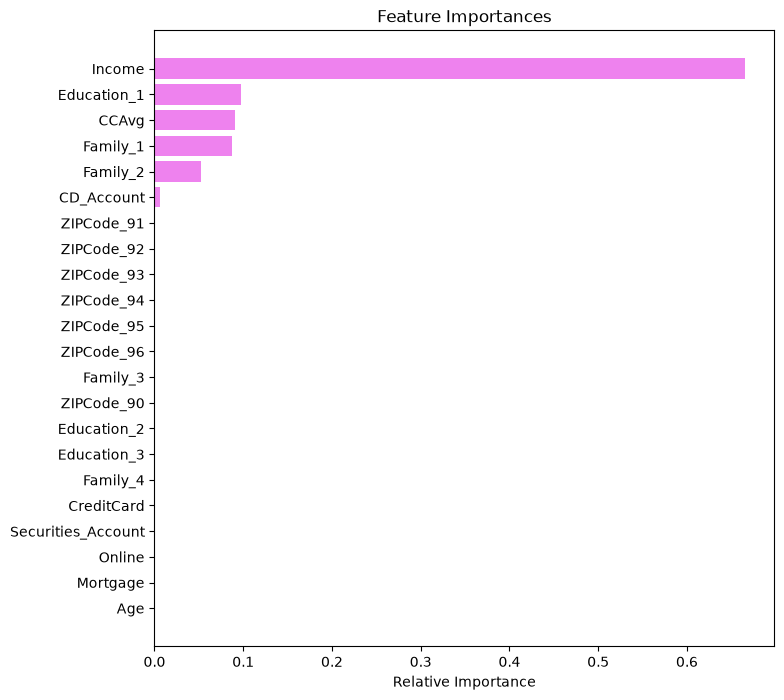

In [133]:
#Plotting feature importances
plot_feature_importances(model4, feature_names)

### Model5 - Class Weights

In [134]:
#Model on scaled data
model5 = DecisionTreeClassifier(criterion='gini', random_state=RS, class_weight={0: 0.1, 1: 0.9})
model5.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 0.1, 1: 0.9}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` featu

In [135]:
#Performance of the model on scaled train data
model5_train_perf = model_performance_classification(model5, X_train, y_train)
model5_train_perf

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [136]:
#Performance of the model on scaled test data
model5_test_perf = model_performance_classification(model5, X_test, y_test)
model5_test_perf

,Accuracy,Recall,Precision,F1
0,0.981,0.9375,0.873786,0.904523


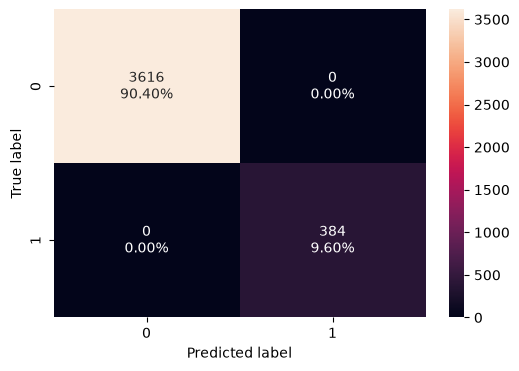

In [137]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model5, X_train, y_train)

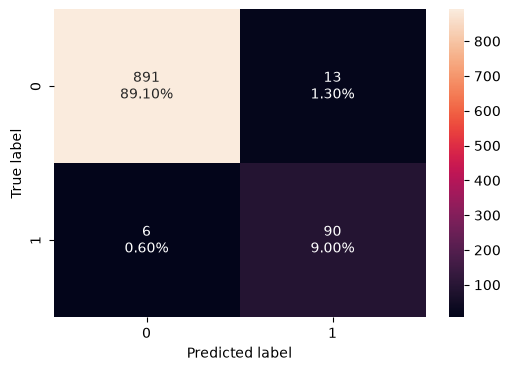

In [138]:
#Confusion Matrix of the model on scaled train data
plot_confusion_matrix(model5, X_test, y_test)

#### Feature names and importances

In [139]:
feature_names = list(X_train.columns)
feature_names

['Age',
 'Income',
 'CCAvg',
 'Mortgage',
 'Securities_Account',
 'CD_Account',
 'Online',
 'CreditCard',
 'Education_1',
 'Education_2',
 'Education_3',
 'Family_1',
 'Family_2',
 'Family_3',
 'Family_4',
 'ZIPCode_90',
 'ZIPCode_91',
 'ZIPCode_92',
 'ZIPCode_93',
 'ZIPCode_94',
 'ZIPCode_95',
 'ZIPCode_96']

In [140]:
importances5 = model5.feature_importances_
indices5 = np.argsort(importances5)
importances5

array([1.72942242e-02, 6.31611321e-01, 9.30362016e-02, 4.51011057e-03,
       1.83555721e-03, 9.08418927e-03, 2.65033036e-03, 3.76829310e-04,
       9.39411698e-02, 4.18431677e-17, 9.44246024e-04, 8.22635020e-02,
       4.94874787e-02, 1.20828837e-03, 6.05623950e-03, 5.35768159e-04,
       8.43146113e-17, 2.06582564e-03, 5.53598339e-04, 3.14137896e-19,
       2.54511952e-03, 0.00000000e+00])

In [141]:
#Print Tree parameters
print_tree_parameters(model5)

Max depth: 17
Max leaf nodes: 92
Min samples split: 2


##### Visualization of the decision tree with scaled and balanced data

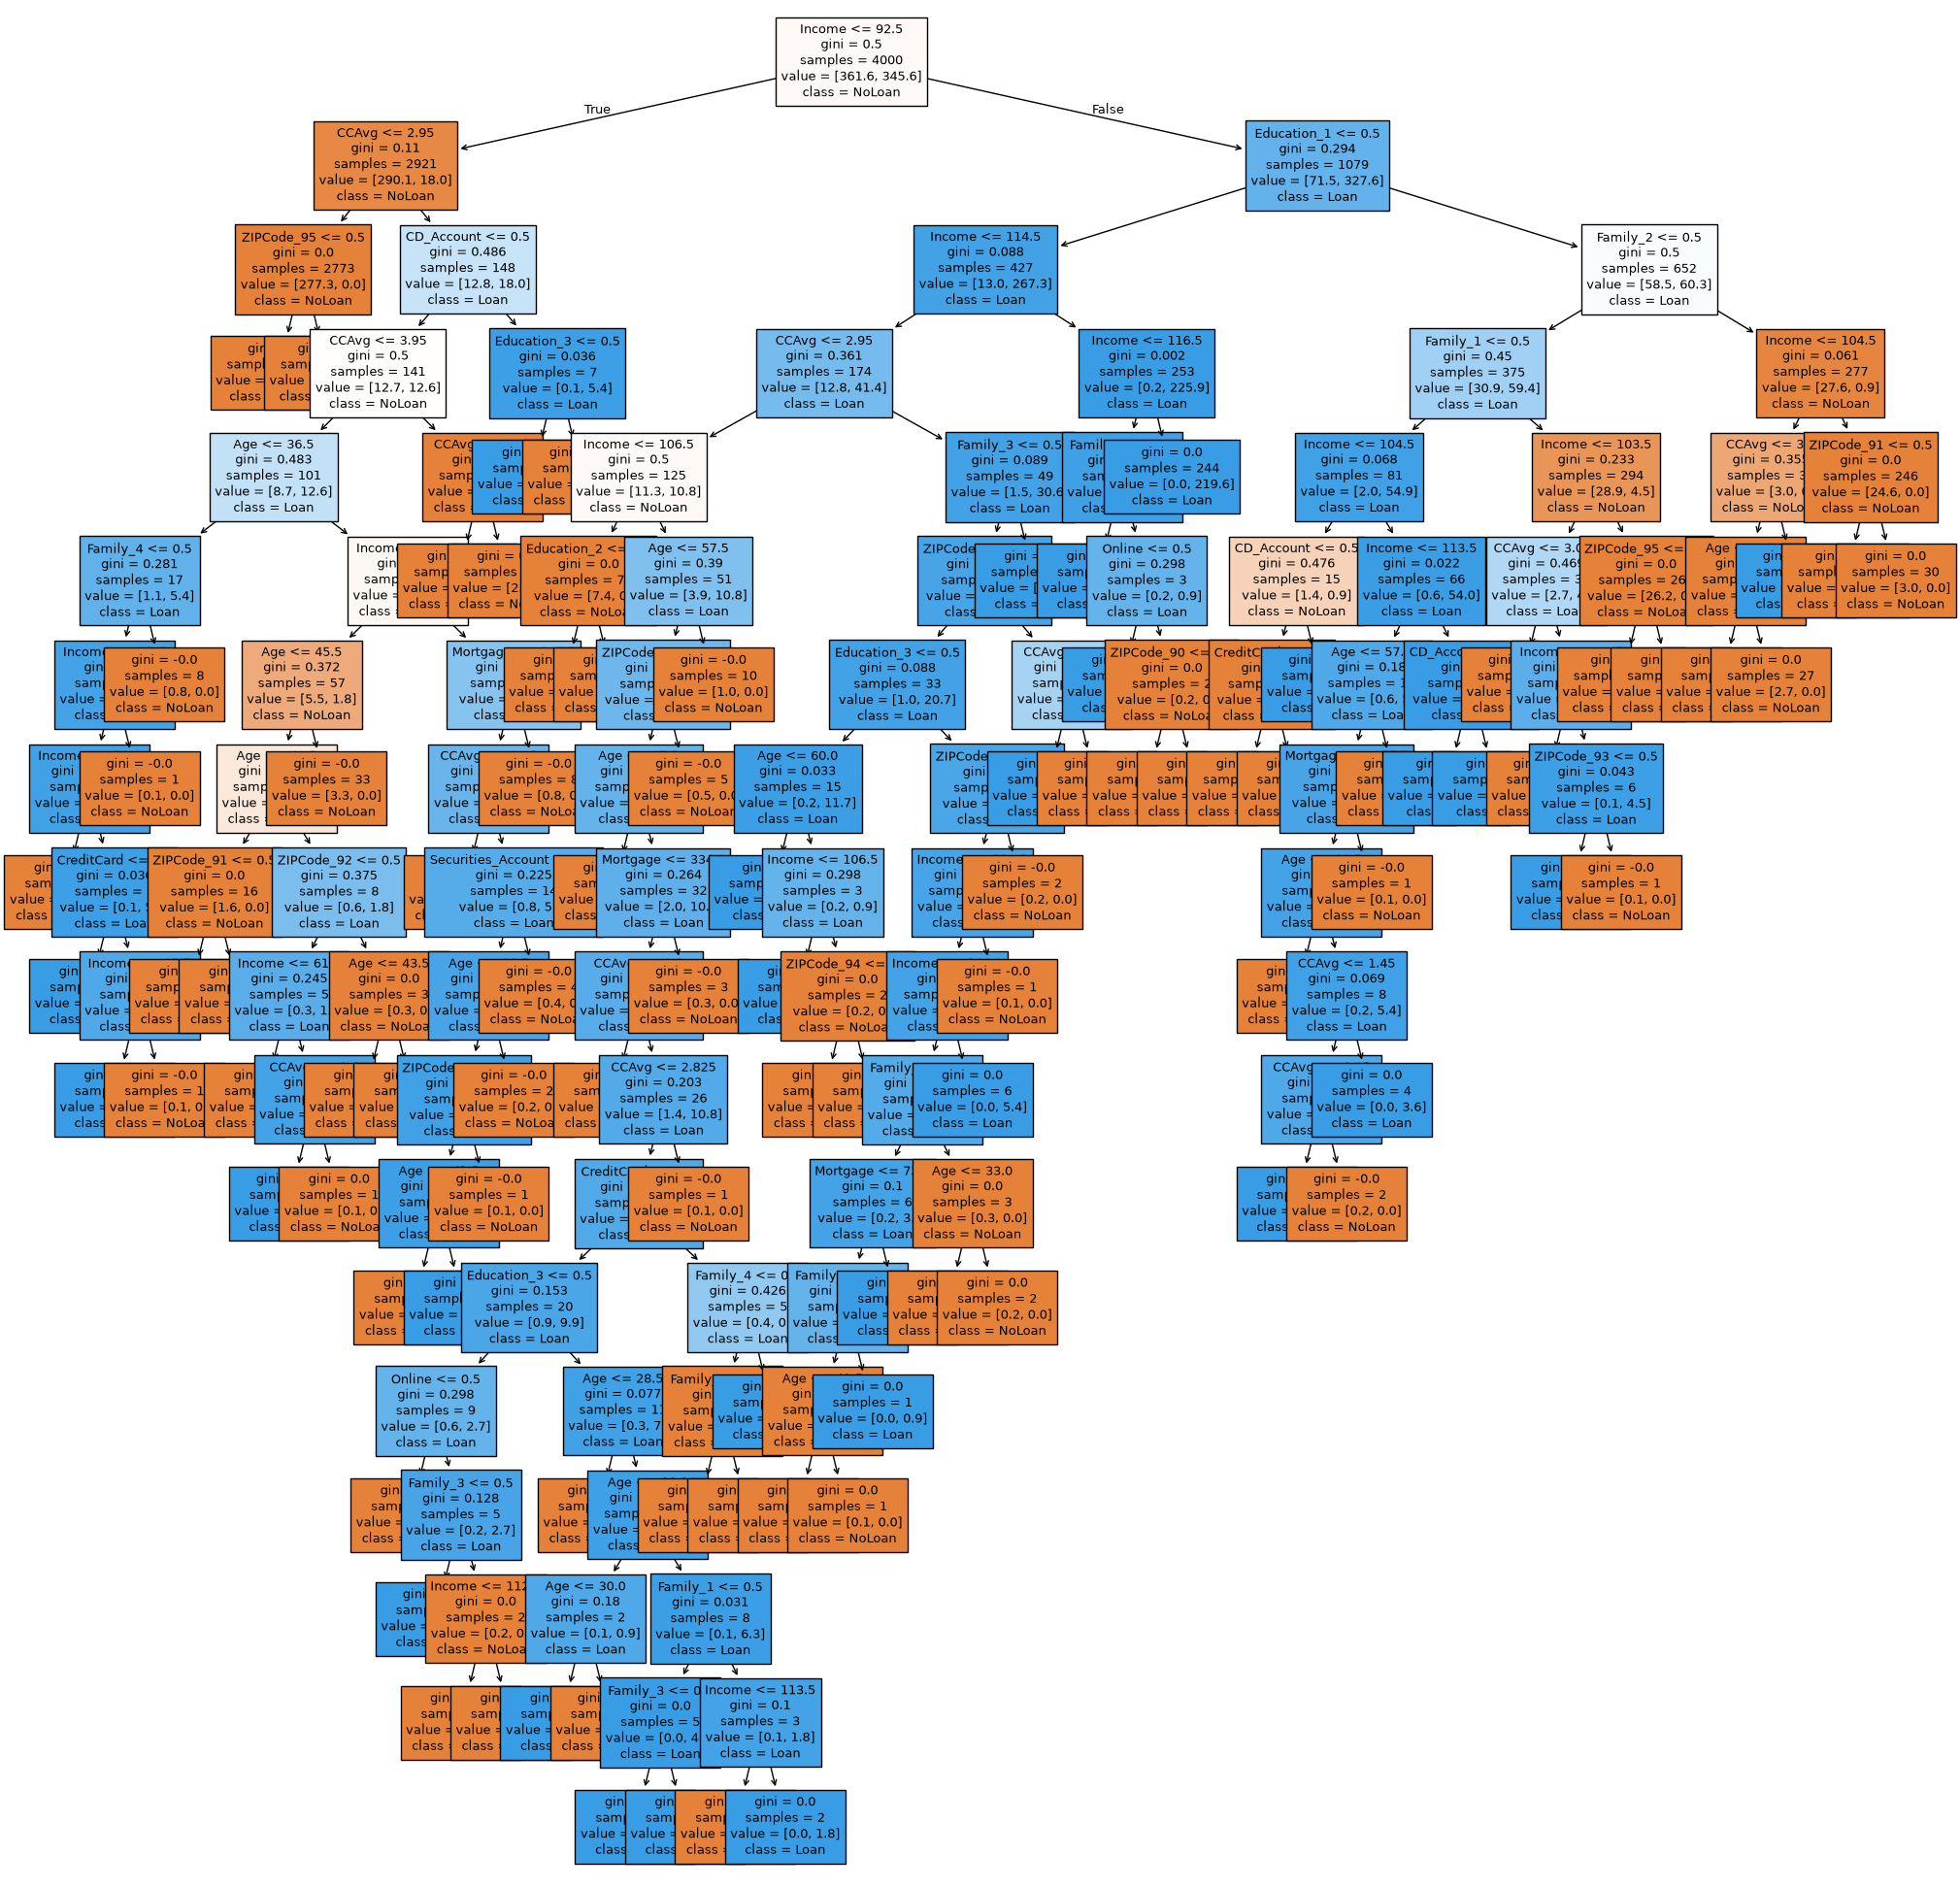

In [142]:
#Decision tree visulization
visualize_tree(model5, feature_names)

In [143]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model5, feature_names)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- ZIPCode_95 <= 0.50
|   |   |   |--- weights: [230.60, 0.00] class: 0
|   |   |--- ZIPCode_95 >  0.50
|   |   |   |--- weights: [46.70, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |--- Family_4 <= 0.50
|   |   |   |   |   |   |--- Income <= 91.50
|   |   |   |   |   |   |   |--- Income <= 59.00
|   |   |   |   |   |   |   |   |--- weights: [0.10, 0.00] class: 0
|   |   |   |   |   |   |   |--- Income >  59.00
|   |   |   |   |   |   |   |   |--- CreditCard <= 0.50
|   |   |   |   |   |   |   |   |   |--- weights: [0.00, 4.50] class: 1
|   |   |   |   |   |   |   |   |--- CreditCard >  0.50
|   |   |   |   |   |   |   |   |   |--- Income <= 85.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 0.90] class: 1
|   |   |   |   |   |   |   |   |   |--- Income >  85.50
|   |   |   |   |   |   |   |   |   |   |--- w

### Model6 - Decision Tree (*No* ZIPCode)

In [144]:

Zip_columns = [col for col in df.columns if  'ZIPCode' in col]
Zip_columns


['ZIPCode_90',
 'ZIPCode_91',
 'ZIPCode_92',
 'ZIPCode_93',
 'ZIPCode_94',
 'ZIPCode_95',
 'ZIPCode_96']

In [145]:
for col in Zip_columns:
  df.drop(col, axis =1, inplace=True)


In [146]:
X=df.drop('Personal_Loan', axis=1)
y = df['Personal_Loan']

In [147]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state = RS)

In [148]:
#Model on scaled data
model6 = DecisionTreeClassifier(criterion='gini', random_state=RS, class_weight={0:0.1, 1:0.9})
model6.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 0.1, 1: 0.9}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` featu

In [149]:
#Performance of the model on scaled train data
model6_train_perf = model_performance_classification(model6, X_train, y_train)
model6_train_perf

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [150]:
#Performance of the model on scaled test data
model6_test_perf = model_performance_classification(model6, X_test, y_test)
model6_test_perf

,Accuracy,Recall,Precision,F1
0,0.985,0.958333,0.893204,0.924623


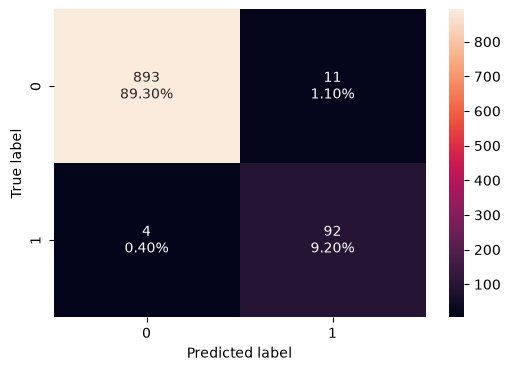

In [151]:
#Confusion Matrix of the basic model on test data
plot_confusion_matrix(model6, X_test, y_test)

In [152]:
feature_names = list(X_train.columns)
print(feature_names)

['Age', 'Income', 'CCAvg', 'Mortgage', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard', 'Education_1', 'Education_2', 'Education_3', 'Family_1', 'Family_2', 'Family_3', 'Family_4']


In [153]:
importances6 = model6.feature_importances_
indices6 = np.argsort(importances6)
importances6

array([2.30908098e-02, 6.32528332e-01, 9.49853511e-02, 5.56290823e-03,
       1.83555721e-03, 1.01121165e-02, 2.86022554e-16, 4.11059115e-04,
       9.39411698e-02, 1.09137958e-04, 3.89785727e-04, 8.35546800e-02,
       4.81215709e-02, 1.54542563e-04, 5.20297910e-03])

In [154]:
#Print Tree parameters
print_tree_parameters(model6)

Max depth: 14
Max leaf nodes: 91
Min samples split: 2


##### Visualization of the decision tree with scaled and balanced data

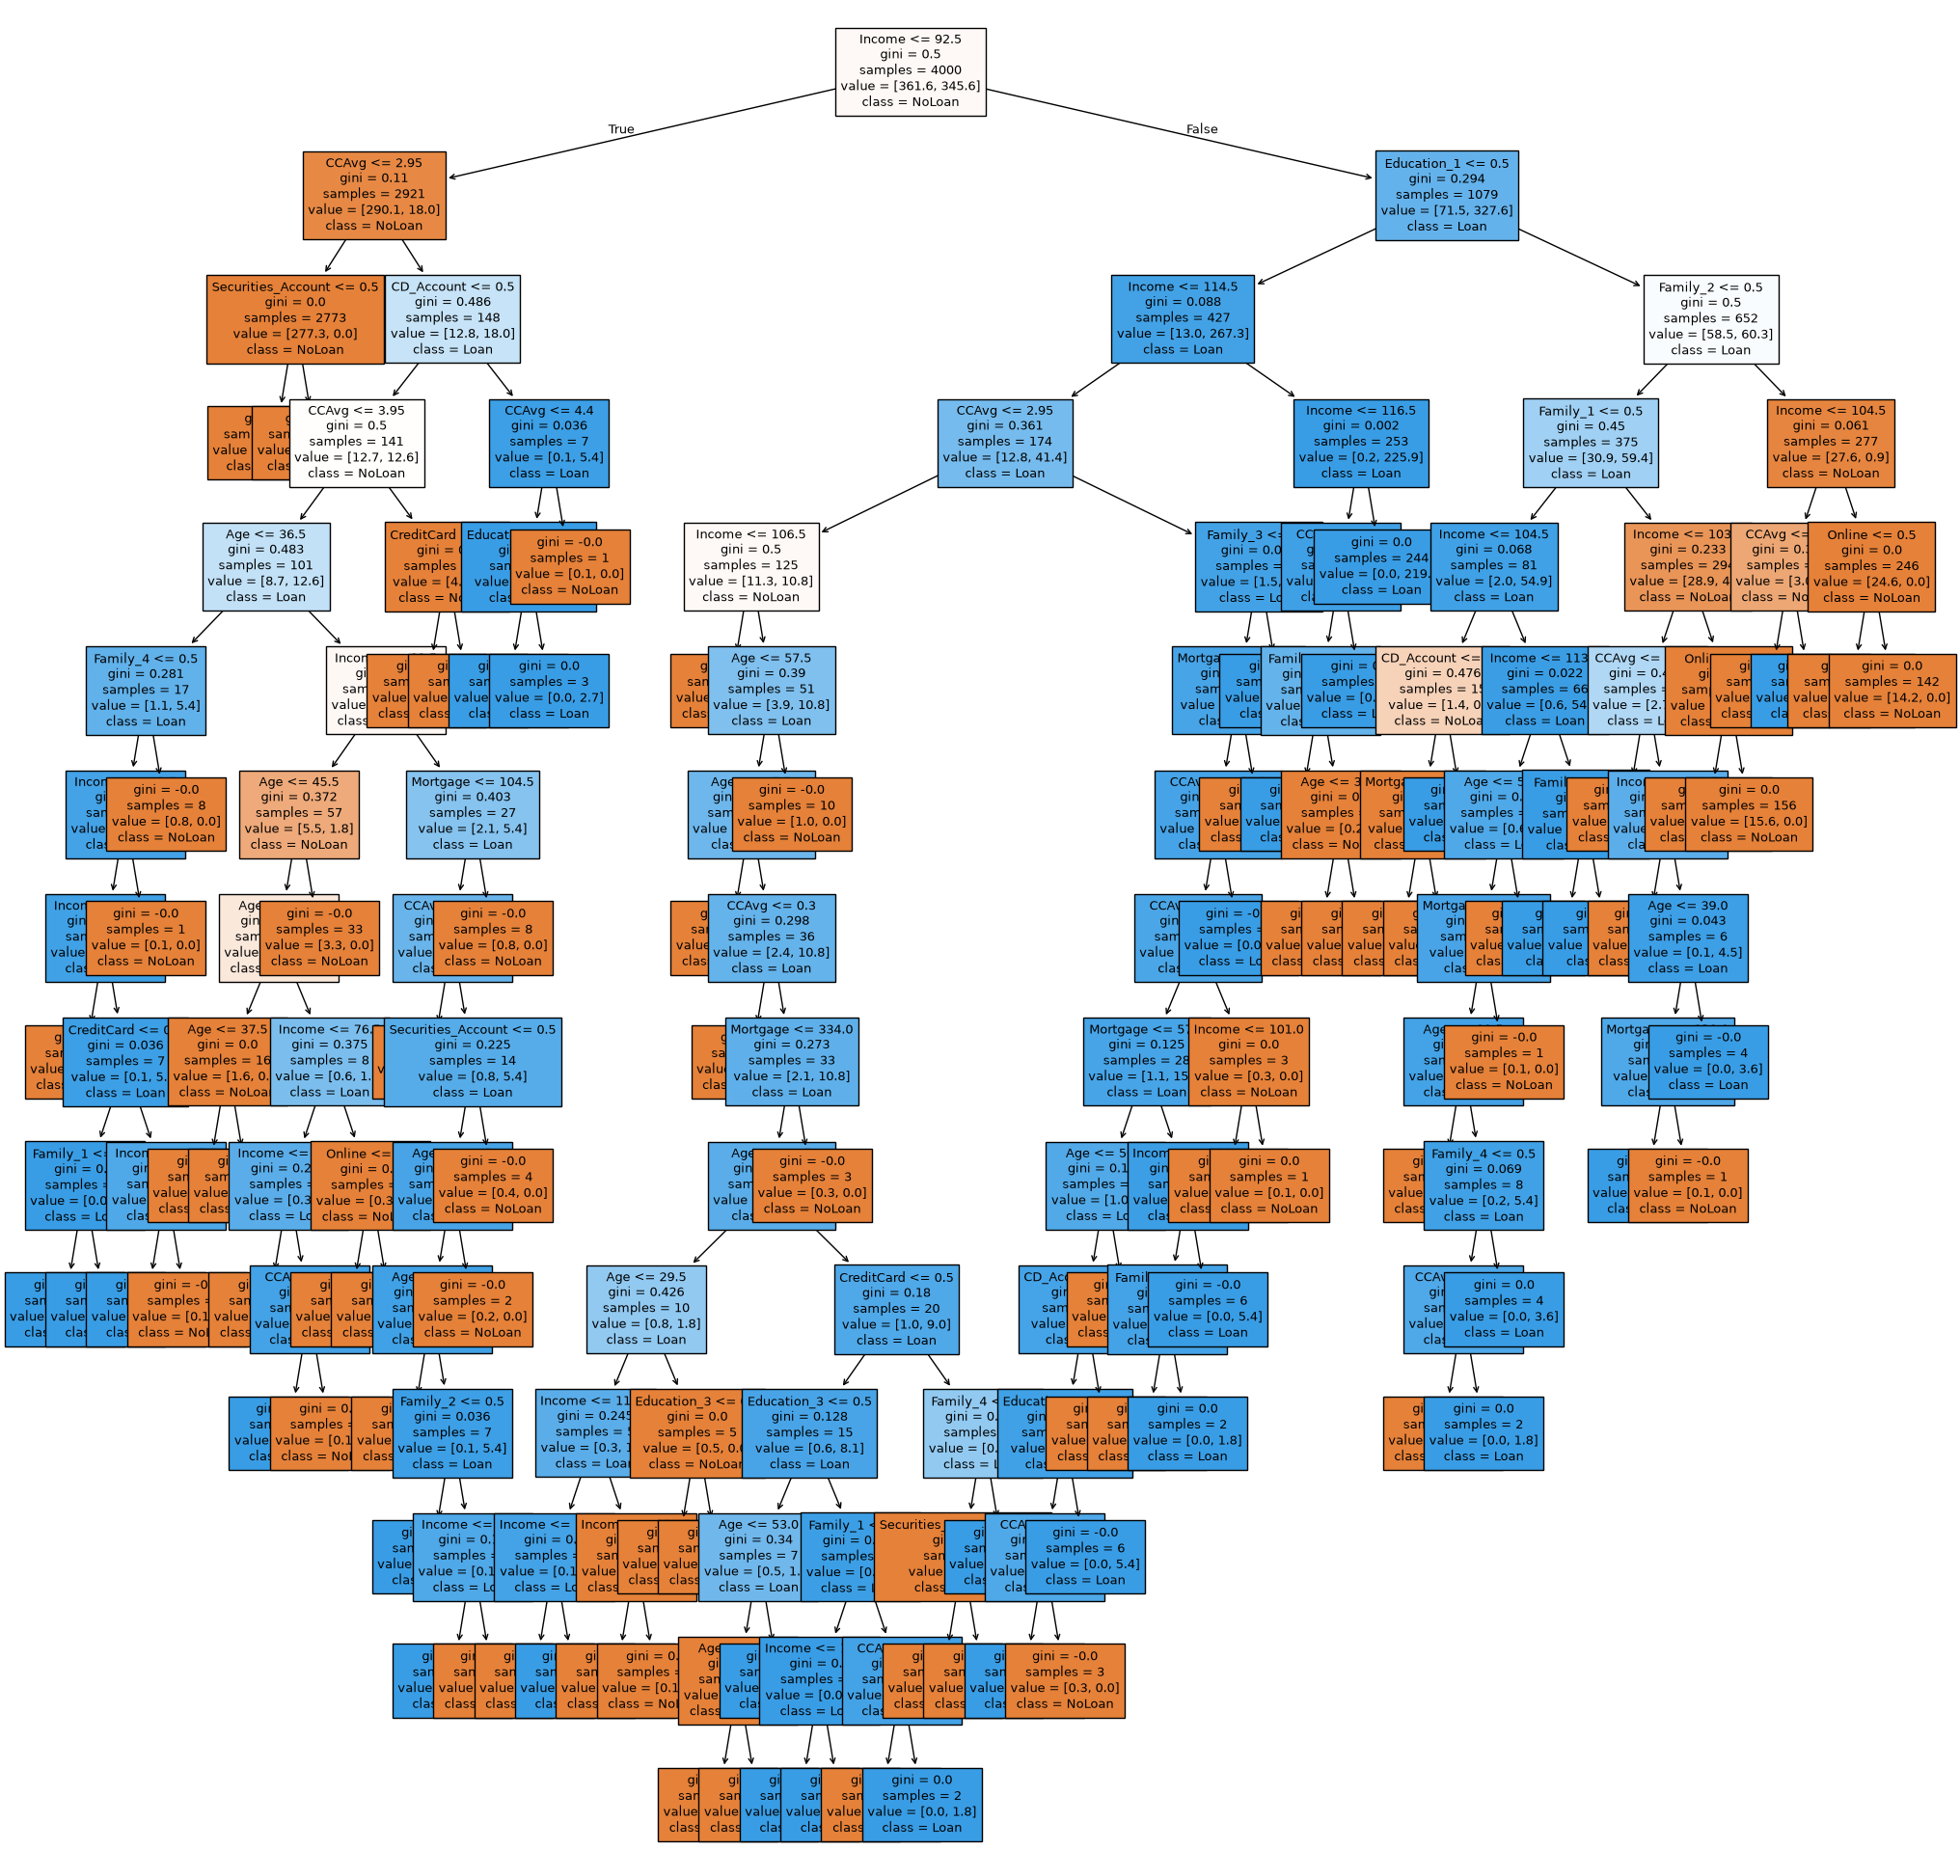

In [155]:
feature_names6 = list(X_train.columns)
#Decision tree visulization
visualize_tree(model6, feature_names6)

In [156]:
#Text report showing the rules of a decision tree -
show_tree_as_text(model6, feature_names6)

|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- Securities_Account <= 0.50
|   |   |   |--- weights: [248.90, 0.00] class: 0
|   |   |--- Securities_Account >  0.50
|   |   |   |--- weights: [28.40, 0.00] class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- Age <= 36.50
|   |   |   |   |   |--- Family_4 <= 0.50
|   |   |   |   |   |   |--- Income <= 91.50
|   |   |   |   |   |   |   |--- Income <= 59.00
|   |   |   |   |   |   |   |   |--- weights: [0.10, 0.00] class: 0
|   |   |   |   |   |   |   |--- Income >  59.00
|   |   |   |   |   |   |   |   |--- CreditCard <= 0.50
|   |   |   |   |   |   |   |   |   |--- Family_1 <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 2.70] class: 1
|   |   |   |   |   |   |   |   |   |--- Family_1 >  0.50
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 1.80] class: 1
|   |   |   |   |   |   |   |   |--- CreditCard >  0.50
|   |   |   |   |   |   

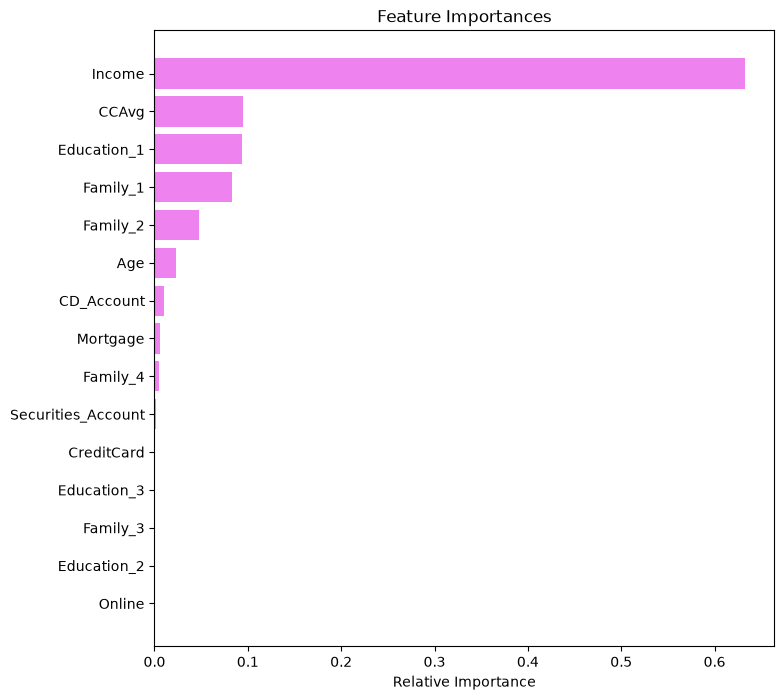

In [157]:
#Plotting feature importances
plot_feature_importances(model6, feature_names6)

## Model Performance Comparison and Final Model Selection

In [158]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        model0_train_perf.T,
        model1_train_perf.T,
        model2_train_perf.T,
        model3_train_perf.T,
        model4_train_perf.T,
        model5_train_perf.T,
        model6_train_perf.T
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Decision Tree (unscaled data)",
    "Decision Tree (scaled data)",
    "Decision Tree (class_weight)",
    "Decision Tree (Pre-Pruning)",
    "Decision Tree (Post-Pruning)",
    "Decision Tree (Unbalanced Weights)",
    "Decision Tree (NoZipCode)"
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Decision Tree (unscaled data),Decision Tree (scaled data),Decision Tree (class_weight),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning),Decision Tree (Unbalanced Weights),Decision Tree (NoZipCode)
Accuracy,1.0,1.0,1.0,0.789250,0.956750,1.0,1.0
Recall,1.0,1.0,1.0,1.000000,0.997396,1.0,1.0
Precision,1.0,1.0,1.0,0.312958,0.690090,1.0,1.0
F1,1.0,1.0,1.0,0.476723,0.815761,1.0,1.0


In [159]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [
        model0_test_perf.T,
        model1_test_perf.T,
        model2_test_perf.T,
        model3_test_perf.T,
        model4_test_perf.T,
        model5_test_perf.T,
        model6_test_perf.T
    ],
    axis=1,
)
models_test_comp_df.columns = [
    "Decision Tree (unscaled data)",
    "Decision Tree (scaled data)",
    "Decision Tree (class_weight)",
    "Decision Tree (Pre-Pruning)",
    "Decision Tree (Post-Pruning)",
    "Decision Tree (Unbalanced Weights)",
    "Decision Tree (NoZipCode)"
]
print("Test set performance comparison:")
models_test_comp_df

Test set performance comparison:


,Decision Tree (unscaled data),Decision Tree (scaled data),Decision Tree (class_weight),Decision Tree (Pre-Pruning),Decision Tree (Post-Pruning),Decision Tree (Unbalanced Weights),Decision Tree (NoZipCode)
Accuracy,0.986000,0.986000,0.982000,0.778000,0.950000,0.981000,0.985000
Recall,0.947917,0.947917,0.947917,1.000000,1.000000,0.937500,0.958333
Precision,0.910000,0.910000,0.875000,0.301887,0.657534,0.873786,0.893204
F1,0.928571,0.928571,0.910000,0.463768,0.793388,0.904523,0.924623


## Observations on the Models and Performance

*   Pre-Pruning model over simplified the data and  reduced the model performance.
*   Pre-Pruning eliminated the importantance of some of the features.
*   The data set here is relatively clean and no missing values. Full tree is giving the better performance than the pruned tree.
*   Probably, the tree is pruned too aggressively and it did not capture the important patterns in the data. Complex relationships among variables have been missed in pruning.

Post-Pruning Model performance

*   Post-Pruning model slightly reduced the model performance on the test data compared to full model.
*   Recall is the most important feature in this analysis. Post pruned model gives best Recall score
*   However, the best post pruned model gave the closest performance on test data compared to train data.
*   The model gives acceptable performance while simplifying.
*   This post-pruned model (model4) may be the optimized model among all the models tested.

Removing ZIPCode showed better performance compared to the full model. May be post pruning on this model may give even better optimized performance.

## Actionable Insights and Business Recommendations


* What recommedations would you suggest to the bank?



*  Income is by far the most dominant feature.

*  Besides Income, Education, Credit card spending, Family Size are the important features.

*  The top 6 important Fetures are Income, Undergraduate Education, CCAvg, SingleMemberFamily, Family of Two and CD_Account

*  Customers with UnderGraduate degree and Income greater than 115,000 dollars are most likely to purchase loan
*   Graduates or professional with higher income but small family size are likely to purchase the loan


*  Cutomers with income less than 92,500 dollars and Credit card spending less than 2,950 dollars are very unlikely to purchase the loan
*   Graduates or professional with higher income with larger family size are not likely to purchase the loan


___